# Genus / family confidence rules for the 768 px model: diversity with three all-pixel estimates

Copy of `Coral_Taxon_Diversity_Live_CD275k_Res768_Regions.ipynb` that compares three versions of the **model, all pixels** estimate. A live coral pixel keeps its genus (family), the head's argmax, only if:
- **all pixels** (as before): always;
- **p1 ≥ 0.5**: the head's top probability is at least 0.5;
- **margin ≥ 0.25**: the top probability exceeds the runner-up's by at least 0.25.

Each taxonomic level is a softmax, so p1 and the margin are comparable across pixels. Pixels that fail the rule stay live coral without a taxon (cover is unchanged). `TAU` = 1% per image applies after the rule. The rules use `<stem>_conf_hist.parquet` (pixel shares binned by p1 and margin in steps of 0.05, so these thresholds are exact), from one run of `scripts/taxon_diversity_predict.py` (output `..._viable_conf`). The ground truth and the model at the points are unchanged. Section 7 compares the rules directly; the original notebook's findings are not repeated.

---


Copy of `Coral_Taxon_Diversity_Live_KL05_Regions.ipynb` with a different model and prediction resolution.

The analysis of `Genus_Diversity_GT_vs_Models.ipynb` at two taxonomic levels, **genus** and **family**, with the setup of
`Coral_Cover_Live_KL05_Regions.ipynb`:
- **Model**: `cbm_cd275000_res768` at step 50k (`/data/vision/beery/scratch/sauder/mermaid-segmentation-final/nbs/model_checkpoints/cbm_cd275000_res768/model_step50000`), trained at 768 px with KL w=0.5 on the taxv2 concept
  table (136 scleractinian genera, 28 families, all with a channel). **Predictions are made at 768 × 768 px.**
- **Live hard coral only.**
  - Ground truth: a point counts if its class maps to `order = scleractinia` with `live` positive. Its genus (family)
    is the positive genus (family) concept; coral labelled only to a higher rank has none.
  - Model: a point or pixel counts if the order head says scleractinia and P(live) > 0.5. Its genus (family) is the
    genus (family) head's argmax, kept only if that is a scleractinian taxon.
- **Sources**: the 33 sources of the cover notebook that are also reliably labelled at that level (section 1). Then
  pooled into **biogeographic regions** (MEOW realms), then **all test data**. A survey of n images draws them at random
  from the group's images.

**Presence of a taxon in an image.**
- **Ground truth**: at least one annotated live coral point of the taxon.
- **Model at the points**: at least one annotated point predicted live coral of the taxon (all points of the image;
  the model doesn't know which points are coral).
- **Model, all pixels**: at least **`TAU` = 1%** of the image's pixels predicted live coral of the taxon.

**Diversity measures**, from a set of images:
- **Richness**: the number of taxa present.
- **Effective number** of taxa: the Hill number of order 1 (exp of the Shannon entropy) of the summed abundances. The
  abundances are point counts for the ground truth and for the model at the points, and pixel shares of the taxa that
  pass `TAU` for all pixels.
- **Taxon-list agreement**: precision is the share of the model's taxa that are annotated; recall is the share of the
  annotated taxa the model finds.
- **Composition similarity**: 1 − Bray–Curtis on relative abundances.

Inputs:
```
python scripts/taxon_diversity_predict.py --split test --sources <the 33 sources> \
    --checkpoint /data/vision/beery/scratch/sauder/mermaid-segmentation-final/nbs/model_checkpoints/cbm_cd275000_res768/model_step50000 \
    --concept-id2name eval_out/scratch100k_hier/cbm_scratch100k_kl_w0.5_taxv2/concept_id2name.json \
    --class-to-concepts nbs/model_checkpoints/cbm_scratch100k_kl_w0.5_taxv2/class_to_concepts.csv \
    --resolution 768 --batch-size 2 \
    --out eval_out/taxon_diversity/test_cd275k_res768_step50000_viable.parquet
```
Bootstrap CIs resample images. Random sampling uses seed `SEED`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

REPO = Path("..").resolve() if Path("../eval_out").exists() else Path(".").resolve()
STEM = REPO / "eval_out/taxon_diversity/test_cd275k_res768_step50000_viable"
CSV = REPO / "nbs/model_checkpoints/cbm_scratch100k_kl_w0.5_taxv2/class_to_concepts.csv"
LEVELS = ("genus", "family")
TAU = 0.01            # minimum pixel share for a taxon to count as present in an image (model, all pixels)
B = 1_000             # bootstrap iterations
R = 300               # random image orders / sets per sample size
N_GRID = [5, 10, 25, 50, 100, 250, 500, 1000, 2500, 5000, 10_000, 25_000]
SEED = 0
# Reliably labelled at a level (as in Genus_Diversity): enough live coral, most of it labelled to that level,
# and at least 3 taxa with 50+ points.
MIN_LIVE_POINTS, MIN_RESOLVED, MIN_TAXA_50 = 500, 0.80, 3

REGIONS = {  # MEOW realm -> sources, as in Coral_Cover_Live_KL05_Regions.ipynb
    "Tropical Atlantic": [1304, 1642, 4091, 5181, 6494, 6702, 7049],
    "Western Indo-Pacific": [2615, 2616, 4721, 4342, 4816],
    "Central Indo-Pacific": [290, 1776, 3350, 6673, 2052, 2955, 3606, 6391, 4957, 7116],
    "Eastern Indo-Pacific": [1990, 2682, 3357, 4280, 6551, 6405, 3697, 5227],
    "Temperate Australasia": [2311, 2655, 3656],
}
REGION_OF = {s: r for r, ss in REGIONS.items() for s in ss}
REGION_COLOR = dict(zip(REGIONS, ["#2a78d6", "#d4a106", "#1baf7a", "#eb6834", "#8a4fd0"]))
ESTIMATES = {  # key -> (label, colour, linestyle, marker filled)
    "truth": ("ground truth (points)", "#1c1c1a", "-", True),
    "model_points": ("model, at the points", "#eb6834", ":", True),
    "model_dense": (f"model, all pixels (≥{TAU:.0%})", "#1baf7a", "-", False),
    "model_dense_p50": ("model, all pixels, p1 ≥ 0.5", "#2a78d6", "--", False),
    "model_dense_m25": ("model, all pixels, margin ≥ 0.25", "#8a4fd0", "-.", False),
}
# Confidence rules for the all-pixel variants: key -> (column of the histogram, threshold); bins are 0.05 wide
RULES = {"model_dense_p50": ("p1_bin", 0.5), "model_dense_m25": ("margin_bin", 0.25)}
MODEL_KEYS = [k for k in ESTIMATES if k != "truth"]
INK, MUTED, GRID, BAND, SURFACE = "#1c1c1a", "#6b6a64", "#e4e3df", "#ebeae6", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 120)
rng = np.random.default_rng(SEED)

pts = pd.read_parquet(f"{STEM}.parquet")
dense = pd.read_parquet(f"{STEM}_dense.parquet")
hist = pd.read_parquet(f"{STEM}_conf_hist.parquet")
conf_pts = pd.read_parquet(f"{STEM}_conf.parquet")  # the same points, plus the heads' top-2 probabilities
img = pd.read_parquet(f"{STEM}_images.parquet").sort_values(["source_id", "image_id"]).reset_index(drop=True)
assert set(img.source_id) == set(REGION_OF), "sources and REGIONS differ"
csv = pd.read_csv(CSV, dtype=str)
scler = csv[csv["order"].str.lower() == "scleractinia"]
TAXA = {lvl: sorted(set(scler[lvl].dropna().str.lower()) - {"not_given", "none"}) for lvl in LEVELS}

# One (images × taxa) matrix per level and estimate over all test images; groups are row subsets.
img_key = img[["source_id", "image_id"]].assign(r=np.arange(len(img)))
row_of = lambda df: df[["source_id", "image_id"]].merge(img_key, how="left", on=["source_id", "image_id"]).r.to_numpy()
MAT = {}
for lvl in LEVELS:
    col = {t: j for j, t in enumerate(TAXA[lvl])}
    MAT[lvl] = {}
    for key, mask, taxon in (("truth", pts.gt_live, pts[f"gt_{lvl}"]),
                             ("model_points", pts.pred_live, pts[f"pred_{lvl}"])):
        sel = mask.to_numpy() & taxon.astype(str).isin(col).to_numpy()
        c = pd.DataFrame({"r": row_of(pts[sel]),
                          "c": taxon[sel].astype(str).map(col).to_numpy()}).value_counts()
        a = np.zeros((len(img), len(col)), dtype=np.float32)
        a[c.index.get_level_values(0), c.index.get_level_values(1)] = c.to_numpy()
        MAT[lvl][key] = a
    d = dense[dense.level == lvl]
    a = np.zeros((len(img), len(col)), dtype=np.float32)
    a[row_of(d), d.taxon.map(col).to_numpy()] = d.share.to_numpy()
    MAT[lvl]["share"] = a
    for key, (bin_col, thr) in RULES.items():  # pixel shares of the pixels that pass the rule
        h = hist[(hist.level == lvl) & (hist[bin_col] >= round(thr * 20))]
        h = h.groupby(["source_id", "image_id", h.taxon.astype(str)], observed=True).share.sum().reset_index()
        a = np.zeros((len(img), len(col)), dtype=np.float32)
        a[row_of(h), h.taxon.map(col).to_numpy()] = h.share.to_numpy()
        MAT[lvl][f"share {key}"] = a


def abundance(lvl, rows, key, tau=TAU):
    """(images × taxa) abundance of an estimate for the given image rows; presence = abundance > 0."""
    if key.startswith("model_dense"):
        s = MAT[lvl]["share" if key == "model_dense" else f"share {key}"][rows]
        return np.where(s >= max(tau, 1e-12), s, 0.0)
    return MAT[lvl][key][rows]


def hill1(abund_sum):
    """Effective number of taxa (exp Shannon) from summed abundances; works on (..., taxa) arrays."""
    total = abund_sum.sum(axis=-1, keepdims=True)
    p = np.divide(abund_sum, total, out=np.zeros_like(abund_sum, dtype=np.float64), where=total > 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.nansum(np.where(p > 0, p * np.log(p), 0.0), axis=-1)
    return np.exp(h)


def legend(fig, keys=ESTIMATES, extra=(), ncol=None, y=1.0):
    handles = []
    for k in keys:
        label, color, ls, filled = ESTIMATES[k]
        handles.append(Line2D([], [], color=color, ls=ls, lw=2, marker="o", mfc=color if filled else SURFACE,
                              mec=color, label=label))
    handles += list(extra)
    fig.legend(handles=handles, loc="upper right", ncol=ncol or len(handles), fontsize=9, bbox_to_anchor=(1, y))


print(f"{img.source_id.nunique()} sources, {len(img):,} images, {len(pts):,} points; "
      + ", ".join(f"{len(TAXA[l])} scleractinian {l if l == 'genus' else 'families'}" for l in LEVELS))

33 sources, 34,138 images, 813,481 points; 136 scleractinian genus, 28 scleractinian families


## 1. Which sources are reliably labelled to genus / family
Of a source's annotated live coral points, the share labelled to the level ("resolved"), and the number of taxa with
50 or more points. A source is used at a level if it has ≥ `MIN_LIVE_POINTS` live coral points, ≥ `MIN_RESOLVED` of
them resolved, and ≥ `MIN_TAXA_50` taxa with 50+ points.

In [2]:
live = pts[pts.gt_live]
elig_rows = []
for s, d in live.groupby("source_id"):
    row = {"source": s, "region": REGION_OF[s], "images": int((img.source_id == s).sum()), "live coral points": len(d)}
    for lvl in LEVELS:
        t = d[f"gt_{lvl}"].astype(str)
        t = t[t.isin(TAXA[lvl])]
        vc = t.value_counts()
        row[f"{lvl}: resolved"] = len(t) / len(d)
        row[f"{lvl}: taxa"] = len(vc)
        row[f"{lvl}: taxa with 50+ pts"] = int((vc >= 50).sum())
        row[f"{lvl}: top"] = ", ".join(f"{k} {v / len(t):.0%}" for k, v in vc.head(3).items())
        row[f"{lvl} ok"] = (len(d) >= MIN_LIVE_POINTS) and (len(t) / len(d) >= MIN_RESOLVED) and (vc >= 50).sum() >= MIN_TAXA_50
    elig_rows.append(row)
ELIG = pd.DataFrame(elig_rows).set_index("source")
ELIG = ELIG.loc[[s for r in REGIONS for s in REGIONS[r] if s in ELIG.index]]
SRC = {lvl: ELIG.index[ELIG[f"{lvl} ok"]].tolist() for lvl in LEVELS}
for lvl in LEVELS:
    print(f"{lvl}: {len(SRC[lvl])} of {len(ELIG)} sources; per region: "
          + ", ".join(f"{r} {sum(s in SRC[lvl] for s in ss)}" for r, ss in REGIONS.items()))
ELIG.style.format({f"{l}: resolved": "{:.0%}" for l in LEVELS})

genus: 18 of 33 sources; per region: Tropical Atlantic 4, Western Indo-Pacific 2, Central Indo-Pacific 4, Eastern Indo-Pacific 6, Temperate Australasia 2
family: 18 of 33 sources; per region: Tropical Atlantic 4, Western Indo-Pacific 2, Central Indo-Pacific 4, Eastern Indo-Pacific 6, Temperate Australasia 2


,region,images,live coral points,genus: resolved,genus: taxa,genus: taxa with 50+ pts,genus: top,genus ok,family: resolved,family: taxa,family: taxa with 50+ pts,family: top,family ok
source,,,,,,,,,,,,,
1304,Tropical Atlantic,111,471,18%,1,1,acropora 100%,False,18%,1,1,acroporidae 100%,False
1642,Tropical Atlantic,146,834,57%,4,3,"porites 71%, montastraea 15%, agaricia 13%",False,57%,4,3,"poritidae 71%, montastraeidae 15%, agariciidae 13%",False
4091,Tropical Atlantic,463,2074,100%,15,6,"agaricia 31%, orbicella 27%, porites 19%",True,100%,10,6,"agariciidae 31%, merulinidae 27%, poritidae 19%",True
5181,Tropical Atlantic,1061,2793,100%,20,9,"agaricia 29%, orbicella 20%, montastraea 15%",True,100%,11,8,"agariciidae 29%, merulinidae 20%, montastraeidae 15%",True
6494,Tropical Atlantic,133,631,93%,9,3,"orbicella 47%, agaricia 23%, porites 10%",True,93%,9,3,"merulinidae 47%, agariciidae 23%, poritidae 10%",True
6702,Tropical Atlantic,1368,2053,100%,12,6,"montastraea 25%, orbicella 21%, porites 16%",True,100%,11,5,"montastraeidae 25%, mussidae 25%, merulinidae 21%",True
7049,Tropical Atlantic,1168,15154,100%,2,1,"acropora 100%, orbicella 0%",False,100%,2,1,"acroporidae 100%, merulinidae 0%",False
2615,Western Indo-Pacific,2493,6578,0%,0,0,,False,0%,0,0,,False
2616,Western Indo-Pacific,2327,5981,0%,0,0,,False,0%,0,0,,False


Groups at each level. Per source: the eligible sources. Per region: the eligible sources of the region, images pooled
(regions with no eligible source are left out). All test: every eligible source.

In [3]:
GROUPS = {}
for lvl in LEVELS:
    by_src = {s: [s] for s in SRC[lvl]}
    by_reg = {r: [s for s in ss if s in SRC[lvl]] for r, ss in REGIONS.items()}
    by_reg = {r: ss for r, ss in by_reg.items() if ss}
    GROUPS[lvl] = {"source": by_src, "region": by_reg, "all": {"all test": SRC[lvl]}}
ROWS = {lvl: {scope: {g: np.flatnonzero(img.source_id.isin(ss).to_numpy()) for g, ss in grp.items()}
              for scope, grp in GROUPS[lvl].items()} for lvl in LEVELS}
pd.DataFrame({(lvl, r): {"sources": len(ss), "images": len(ROWS[lvl]["region"][r])}
              for lvl in LEVELS for r, ss in GROUPS[lvl]["region"].items()}).T

sources  images
genus  Tropical Atlantic            4    3025
       Western Indo-Pacific         2    3373
       Central Indo-Pacific         4   12194
       Eastern Indo-Pacific         6    4988
       Temperate Australasia        2     471
family Tropical Atlantic            4    3025
       Western Indo-Pacific         2    3373
       Central Indo-Pacific         4   12414
       Eastern Indo-Pacific         6    4988
       Temperate Australasia        2     471

Helpers shared by every level and scope. Bootstrap sums and random image sets are computed as weight matrices ×
abundance matrices, so pooled groups of tens of thousands of images stay cheap.

In [4]:
def boot_sums(a, n_boot, chunk=100):
    """(n_boot, taxa) bootstrap sums over images of a (images × taxa): multinomial image weights × a."""
    n = a.shape[0]
    out = []
    for i in range(0, n_boot, chunk):
        w = rng.multinomial(n, np.full(n, 1 / n), size=min(chunk, n_boot - i)).astype(np.float32)
        out.append(w @ a)
    return np.concatenate(out)


def summarize(lvl, scope):
    res = {}
    for g, rows in ROWS[lvl][scope].items():
        gt = abundance(lvl, rows, "truth")
        gt_sum = gt.sum(axis=0)
        gt_present, gt_rel = gt_sum > 0, gt_sum / gt_sum.sum()
        w = rng.multinomial(len(rows), np.full(len(rows), 1 / len(rows)), size=B).astype(np.float32)  # paired
        r = {}
        for key in ESTIMATES:
            a = abundance(lvl, rows, key)
            s = a.sum(axis=0)
            present = s > 0
            boot = hill1(w @ a)
            rel = s / s.sum() if s.sum() > 0 else np.zeros_like(gt_rel)
            r[key] = {"richness": int(present.sum()), "effective": hill1(s),
                      "eff lo": np.quantile(boot, 0.025), "eff hi": np.quantile(boot, 0.975),
                      "precision": (present & gt_present).sum() / max(present.sum(), 1),
                      "recall": (present & gt_present).sum() / gt_present.sum(),
                      "composition similarity": 1 - np.abs(rel - gt_rel).sum() / 2}
        res[g] = r
    t = pd.concat({g: pd.DataFrame(r).T for g, r in res.items()}, names=["group", "estimate"]).unstack("estimate")
    t["images"] = [len(ROWS[lvl][scope][g]) for g in t.index]
    t["sources"] = [len(GROUPS[lvl][scope][g]) for g in t.index]
    return t


def show_summary(t, lvl):
    out = pd.DataFrame(index=t.index)
    if (t.sources > 1).any():
        out["sources"] = t.sources
    out["images"] = t.images
    for k in ESTIMATES:
        out[("richness", ESTIMATES[k][0])] = t[("richness", k)].astype(int)
    for k in ESTIMATES:
        out[("effective", ESTIMATES[k][0])] = [f"{v:.1f} [{lo:.1f}, {hi:.1f}]" for v, lo, hi in
                                               zip(t[("effective", k)], t[("eff lo", k)], t[("eff hi", k)])]
    for m in ("precision", "recall", "composition similarity"):
        for k in MODEL_KEYS:
            out[(m, ESTIMATES[k][0])] = t[(m, k)].round(2)
    out.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, "") for c in out.columns])
    out.index.name = lvl
    return out


def accumulation(lvl, rows, keys=tuple(ESTIMATES)):
    """Richness and recall after n random images: median and 95% band over R random orders (same for all keys)."""
    n_all = len(rows)
    grid = [n for n in N_GRID if n < n_all] + [n_all]
    ranks = np.argsort(np.argsort(rng.random((R, n_all)), axis=1), axis=1)  # rank of each image in each order
    gt_present = abundance(lvl, rows, "truth").sum(axis=0) > 0
    out = []
    for key in keys:
        present = abundance(lvl, rows, key) > 0
        first = np.full((R, present.shape[1]), np.inf)
        for j in np.flatnonzero(present.any(axis=0)):
            first[:, j] = ranks[:, present[:, j]].min(axis=1)  # position at which taxon j is first seen
        for n in grid:
            found = first < n
            rich = found.sum(axis=1)
            rec = (found & gt_present).sum(axis=1) / gt_present.sum()
            q, rq = np.quantile(rich, [0.025, 0.5, 0.975]), np.quantile(rec, [0.025, 0.5, 0.975])
            out.append({"n": n, "estimate": key, "rich lo": q[0], "rich": q[1], "rich hi": q[2],
                        "recall lo": rq[0], "recall": rq[1], "recall hi": rq[2]})
    return pd.DataFrame(out)


def hill_curve(lvl, rows):
    """Effective number from R random sets of n images (without replacement): median and 95% band."""
    n_all = len(rows)
    ab = {k: abundance(lvl, rows, k).astype(np.float32) for k in ESTIMATES}
    out = []
    for n in [m for m in N_GRID if m < n_all] + [n_all]:
        w = np.zeros((R, n_all), dtype=np.float32)
        np.put_along_axis(w, np.argsort(rng.random((R, n_all)), axis=1)[:, :n], 1.0, axis=1)
        for k in ESTIMATES:
            q = np.quantile(hill1(w @ ab[k]), [0.025, 0.5, 0.975])
            out.append({"n": n, "estimate": k, "lo": q[0], "median": q[1], "hi": q[2]})
    return pd.DataFrame(out)


def grid_plot(curves, summaries, lvl, scope, kind, ncols, panel=(3.6, 2.9), keys=tuple(ESTIMATES)):
    """kind: 'rich' / 'recall' (accumulation) or 'hill' (effective number)."""
    groups = list(curves)
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel[0] * ncols, panel[1] * nrows + 0.7), squeeze=False)
    for ax, g in zip(axes.flat, groups):
        c0 = curves[g]
        for key in keys:
            label, color, ls, _ = ESTIMATES[key]
            c = c0[c0.estimate == key]
            lo, mid, hi = ("lo", "median", "hi") if kind == "hill" else (f"{kind} lo", kind, f"{kind} hi")
            ax.fill_between(c.n, c[lo], c[hi], color=color, alpha=0.12, lw=0)
            ax.plot(c.n, c[mid], color=color, ls=ls, lw=2)
        s = summaries.loc[g]
        if kind == "rich":
            ax.axhline(s[("richness", "truth")], color=INK, lw=1, ls="--")
        elif kind == "recall":
            ax.axhline(1, color=INK, lw=1, ls="--")
            ax.set_ylim(0, 1.05)
            ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
        else:
            ax.axhline(s[("effective", "truth")], color=INK, lw=1, ls="--")
            ax.set_ylim(bottom=0)
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
        color = REGION_COLOR.get(REGION_OF.get(g, g), INK)
        ax.set_title(f"{g}: {int(s[('richness', 'truth')])} taxa ({s[('effective', 'truth')]:.1f} eff.), "
                     f"{int(s['images'].iloc[0]) if hasattr(s['images'], 'iloc') else int(s['images']):,} img",
                     fontsize=9, color=color)
    for ax in axes.flat[len(groups):]:
        ax.axis("off")
    ylab = {"rich": f"{lvl} found", "recall": f"annotated {lvl} found", "hill": f"effective number of {lvl}"}[kind]
    for ax in axes[:, 0]:
        ax.set_ylabel(ylab)
    for ax in axes[-1]:
        ax.set_xlabel("images (n)")
    legend(fig, keys=keys)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.7 / (panel[1] * nrows + 0.7)))
    plt.show()


MARKERS = {"model_points": "o", "model_dense": "s", "model_dense_p50": "^", "model_dense_m25": "D"}


def ratio_plot(t, lvl, title):
    """Richness and effective number, model / ground truth, and taxon-list precision / recall per group."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    colors = [REGION_COLOR.get(REGION_OF.get(g, g), INK) for g in t.index]
    for ax, metric in zip(axes[:2], ("richness", "effective")):
        gt = t[(metric, "truth")]
        for key, marker in MARKERS.items():
            filled = ESTIMATES[key][3]
            ax.scatter(gt, t[(metric, key)], s=45, marker=marker, c=colors if filled else SURFACE,
                       edgecolors=colors, lw=1.5, zorder=3)
        top = max([gt.max()] + [t[(metric, k)].max() for k in MODEL_KEYS]) * 1.08
        ax.plot([0, top], [0, top], color=INK, lw=1, ls="--")
        ax.set_xlim(0, top)
        ax.set_ylim(0, top)
        ax.set_xlabel(f"ground truth ({metric})")
        ax.set_ylabel(f"model ({metric})")
        ax.set_title(f"{metric.capitalize()} of {lvl} (dashed: 1:1)")
    ax = axes[2]
    for key, marker in MARKERS.items():
        filled = ESTIMATES[key][3]
        ax.scatter(t[("recall", key)], t[("precision", key)], s=45, marker=marker, c=colors if filled else SURFACE,
                   edgecolors=colors, lw=1.5, zorder=3)
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel(f"recall: share of annotated {lvl} found")
    ax.set_ylabel(f"precision: share of model {lvl} annotated")
    ax.set_title(f"{lvl.capitalize()} list agreement")
    handles = [Patch(color=c, label=r) for r, c in REGION_COLOR.items()]
    handles += [Line2D([], [], color=MUTED, marker=m, mfc=MUTED if ESTIMATES[k][3] else SURFACE, lw=0,
                       label=ESTIMATES[k][0]) for k, m in MARKERS.items()]
    fig.legend(handles=handles, loc="upper right", ncol=7, fontsize=8)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()

## 2. Genera
### 2.1 Per source
From all of a source's images: richness, effective number (95% bootstrap CI), genus-list precision and recall, and
composition similarity. Sources grouped by region (marker colour in the figure).

images              richness                                                                                                                       effective                                                                           \
             ground truth (points) model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 ground truth (points) model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5   
genus                                                                                                                                                                                                                                         
4091     463                    15                   18                      16                          14                               15        5.5 [5.1, 5.8]       5.7 [5.2, 6.1]          5.3 [4.9, 5.6]              5.0 [4.6, 5.2]   
5181    1061                    20                   25                      24                          19                               20        7.3 [6.7, 7.7]       7.4 [6.6, 8.0]          7.0 [6.3, 7.5]              6.3 [5.6, 6.8]   
6494     133                     9                   14                      17                          10                               10        4.7 [3.8, 5.5]       5.6 [3.9, 6.6]          5.7 [4.0, 6.8]              4.6 [3.3, 5.7]   
6702    1368                    12                   34                      33                          27                               28        6.7 [6.3, 7.1]       8.9 [8.0, 9.4]          8.5 [7.7, 9.0]              7.4 [6.8, 7.9]   
4721    2909                    34                   43                      42                          33                               34        8.2 [7.6, 8.7]       6.1 [5.8, 6.4]          5.4 [5.1, 5.7]              4.2 [4.0, 4.4]   
4342     464                    37                   36                      33                          26                               27     13.6 [12.6, 14.3]    12.0 [11.2, 12.6]         9.9 [9.1, 10.5]              7.1 [6.5, 7.6]   
290      227                    22                   25                      31                          23                               24        7.7 [6.1, 8.7]       7.5 [6.2, 8.5]          6.9 [5.8, 7.7]              5.3 [4.5, 6.0]   
3606    2185                    32                   39                      38                          32                               33     12.8 [12.2, 13.2]     10.4 [9.9, 10.8]         9.8 [9.4, 10.1]              8.7 [8.3, 9.0]   
4957    9012                    41                   39                      43                          38                               39        6.6 [6.3, 6.9]       7.1 [6.7, 7.4]          6.5 [6.3, 6.8]              5.5 [5.3, 5.7]   
7116     770                    18                   29                      22                          16                               18      10.3 [9.7, 10.8]      9.8 [9.1, 10.5]          5.0 [4.4, 5.5]              4.2 [3.7, 4.6]   
1990    1233                     4                    9                       8                           7                                7        1.9 [1.8, 2.0]       1.8 [1.7, 1.9]          1.8 [1.7, 1.9]              1.7 [1.7, 1.8]   
2682     675                     5                   10                       8                           7                                7        2.4 [2.2, 2.5]       2.2 [2.0, 2.4]          2.2 [2.0, 2.3]              2.0 [1.9, 2.2]   
3357     564                     6                    8                       9                           7                                6        2.3 [2.1, 2.4]       2.2 [2.0, 2.4]          2.2 [2.0, 2.4]              2.1 [1.9, 2.3]   
6405    1332                     7                    8                       9                           8                                8        2.9 [2.6, 3.2]       2.8 [2.5, 3.0

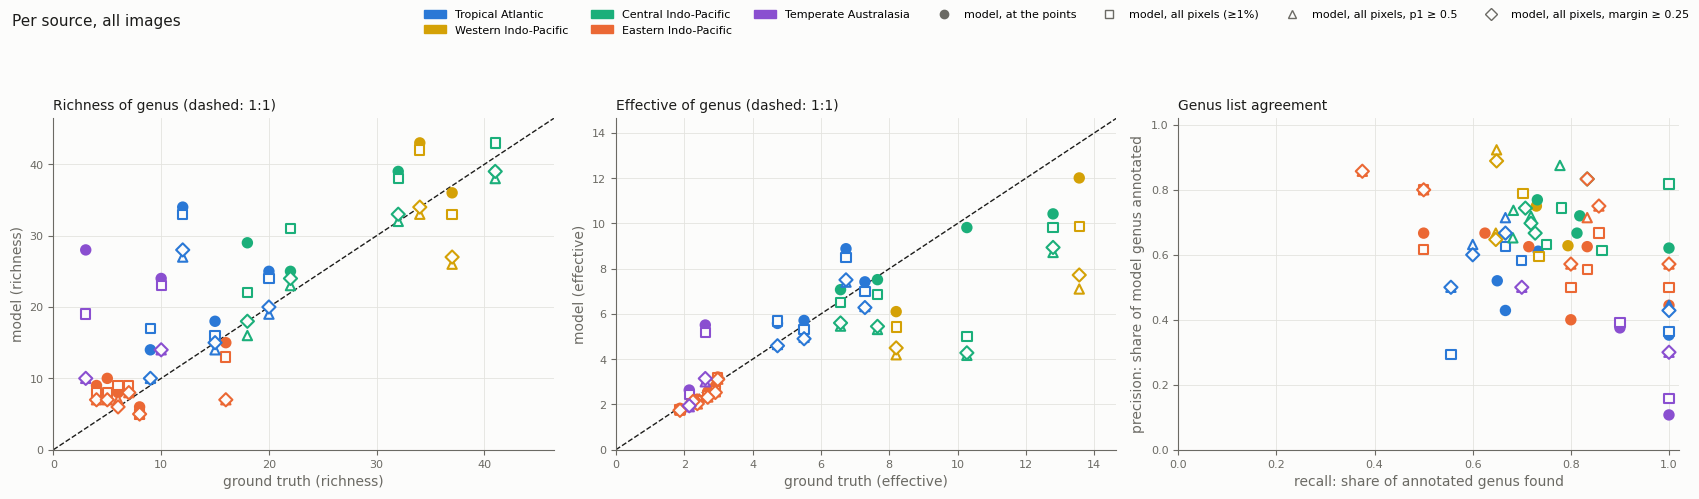

In [5]:
S_GENUS = {scope: summarize("genus", scope) for scope in ("source", "region", "all")}
display(show_summary(S_GENUS["source"], "genus"))
ratio_plot(S_GENUS["source"], "genus", "Per source, all images")

Accumulation per source: genus found after n random images (median, 95% band over `R` random orders; dashed: annotated
genus, all images).

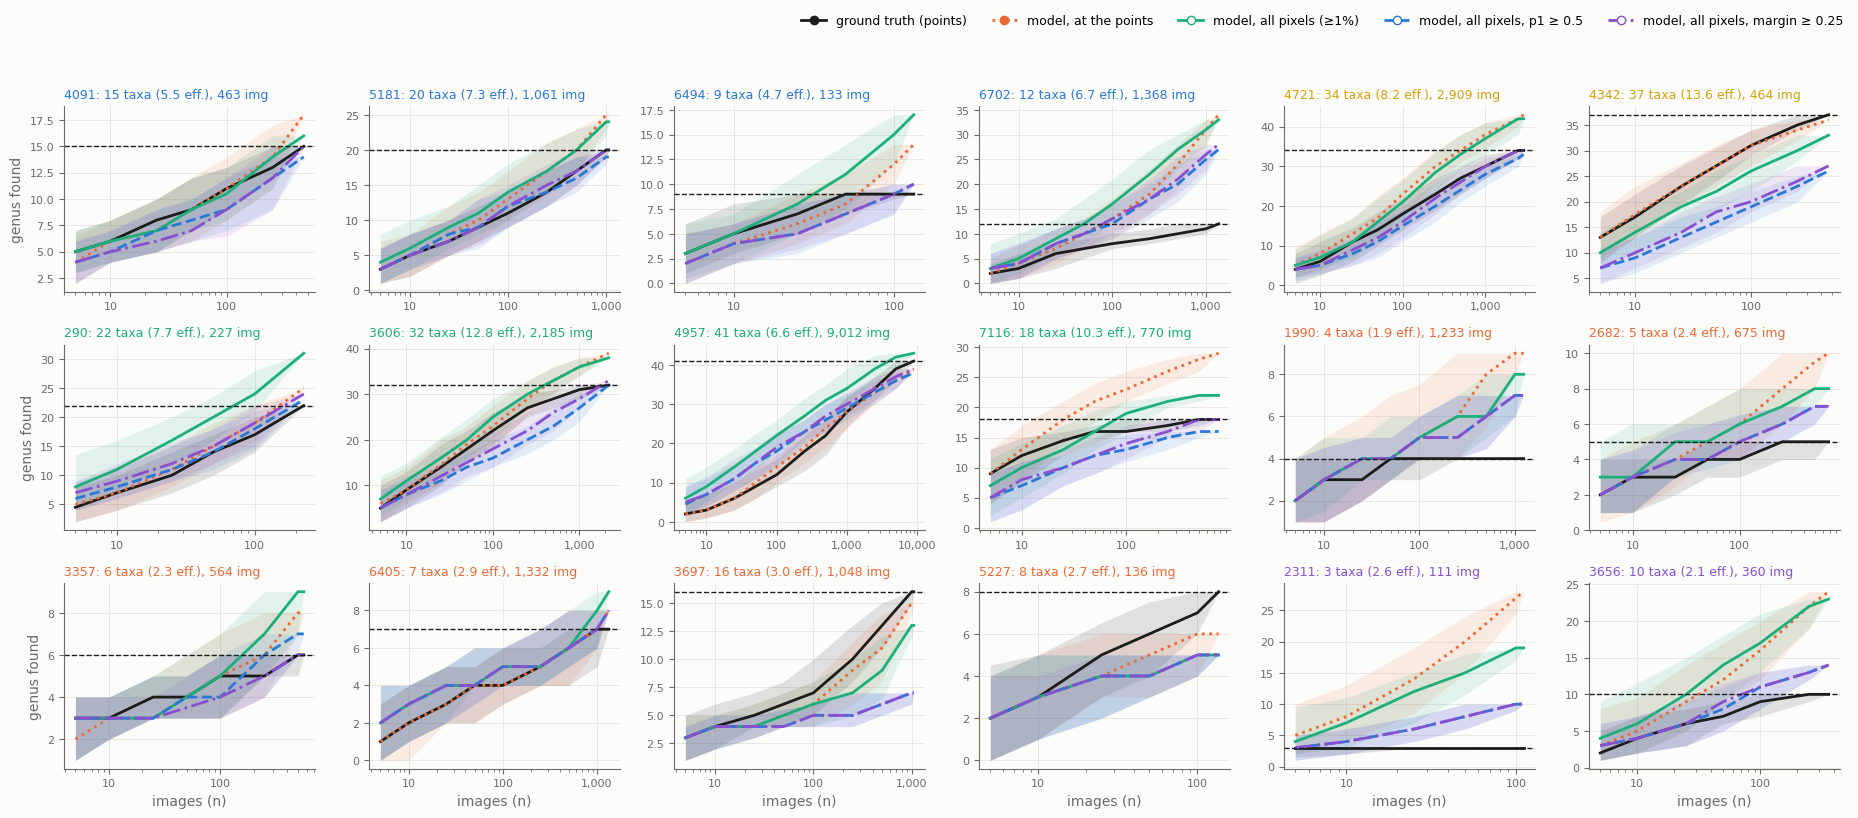

In [6]:
ACC_GENUS_SRC = {g: accumulation("genus", rows) for g, rows in ROWS["genus"]["source"].items()}
grid_plot(ACC_GENUS_SRC, S_GENUS["source"], "genus", "source", "rich", ncols=6, panel=(3.1, 2.5))

### 2.2 Per region (images pooled across the region's sources)

sources images              richness                                                                                                                       effective                                               ...  \
                                     ground truth (points) model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 ground truth (points) model, at the points model, all pixels (≥1%)  ...   
genus                                                                                                                                                                                                                                    ...   
Tropical Atlantic           4   3025                    23                   40                      39                          30                               31        7.7 [7.3, 8.0]       8.7 [8.2, 9.1]          9.1 [8.5, 9.4]  ...   
Western Indo-Pacific        2   3373                    46                   46                      46                          36                               37     13.1 [12.3, 13.6]       8.7 [8.3, 9.0]          7.1 [6.8, 7.4]  ...   
Central Indo-Pacific        4  12194                    50                   46                      48                          41                               42     14.9 [14.3, 15.3]    12.7 [12.2, 13.0]          9.3 [9.0, 9.6]  ...   
Eastern Indo-Pacific        6   4988                    18                   19                      17                          10                               10        2.8 [2.6, 2.9]       2.7 [2.6, 2.9]          2.5 [2.4, 2.6]  ...   
Temperate Australasia       2    471                    11                   34                      29                          18                               17        2.6 [2.3, 3.0]       3.9 [3.2, 4.6]          2.9 [2.5, 3.4]  ...   

                                        precision                                                recall                                                                                      composition similarity                          \
                      model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25   model, at the points model, all pixels (≥1%)   
genus                                                                                                                                                                                                                                         
Tropical Atlantic                            0.43                             0.42                 0.61                    0.65                        0.57                             0.57                   0.91                    0.89   
Western Indo-Pacific                         0.78                             0.76                 0.74                    0.72                        0.61                             0.61                   0.75                    0.71   
Central Indo-Pacific                         0.83                             0.83                 0.76                    0.78                        0.68                             0.70                   0.82                    0.75   
Eastern Indo-Pacific                         0.80                             0.80                 0.67                    0.61                        0.44                             0.44                   0.98                    0.97   
Temperate Australasia                        0.44                             0.47                 0.91                    0.91                        0.73                             0.73                   0.85                    0.90   

                                                                                    
                      model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25  
genus             

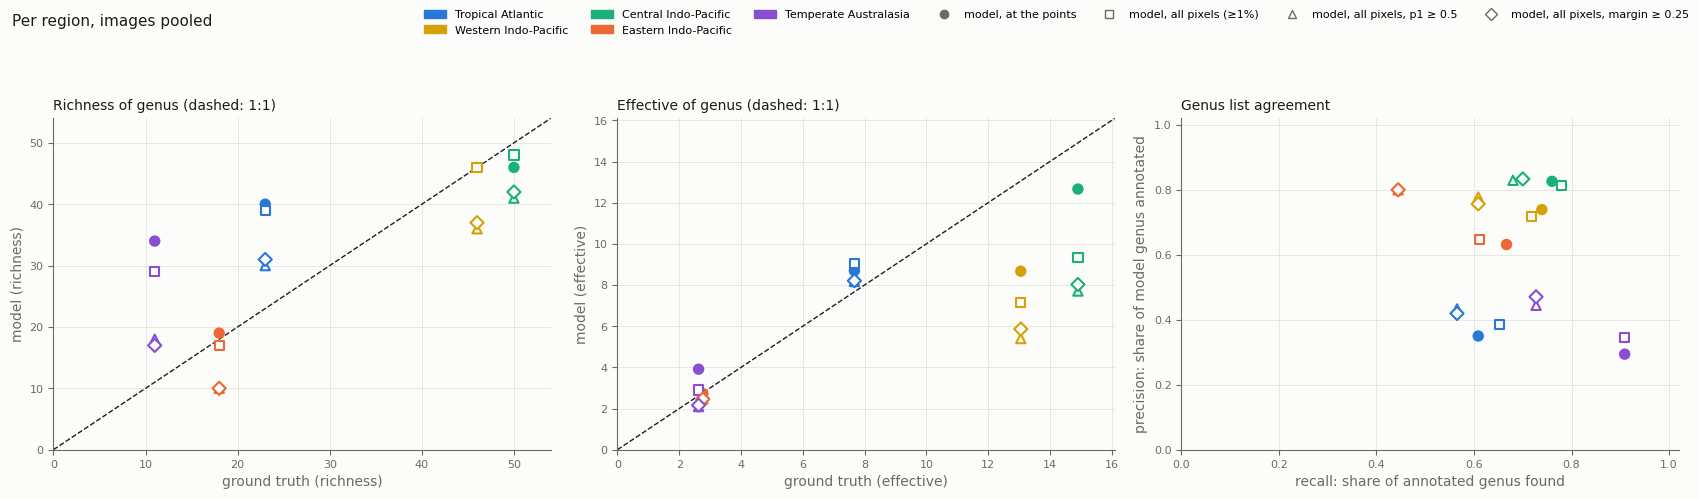

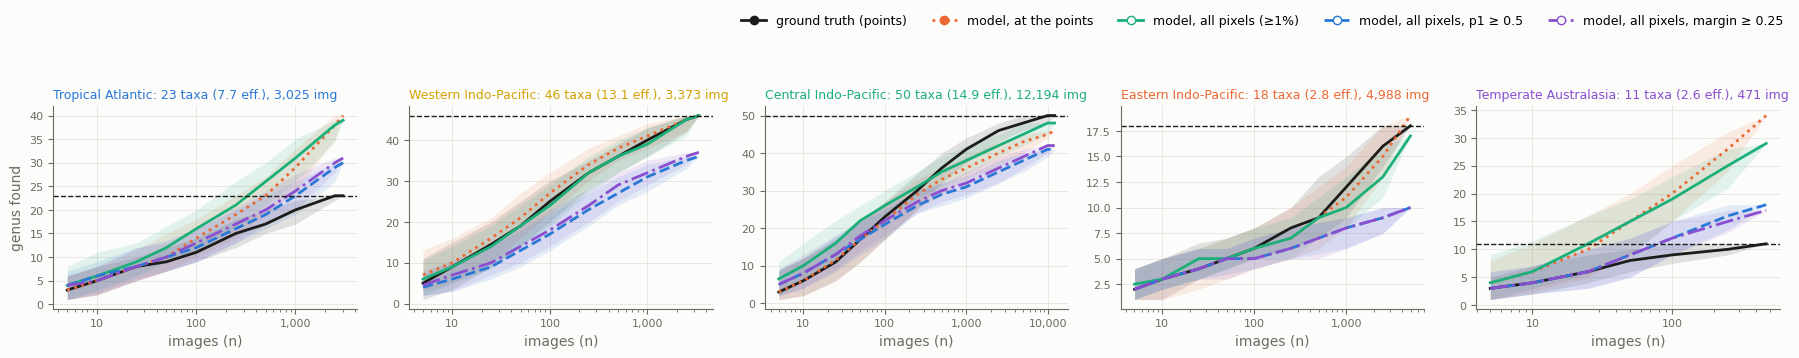

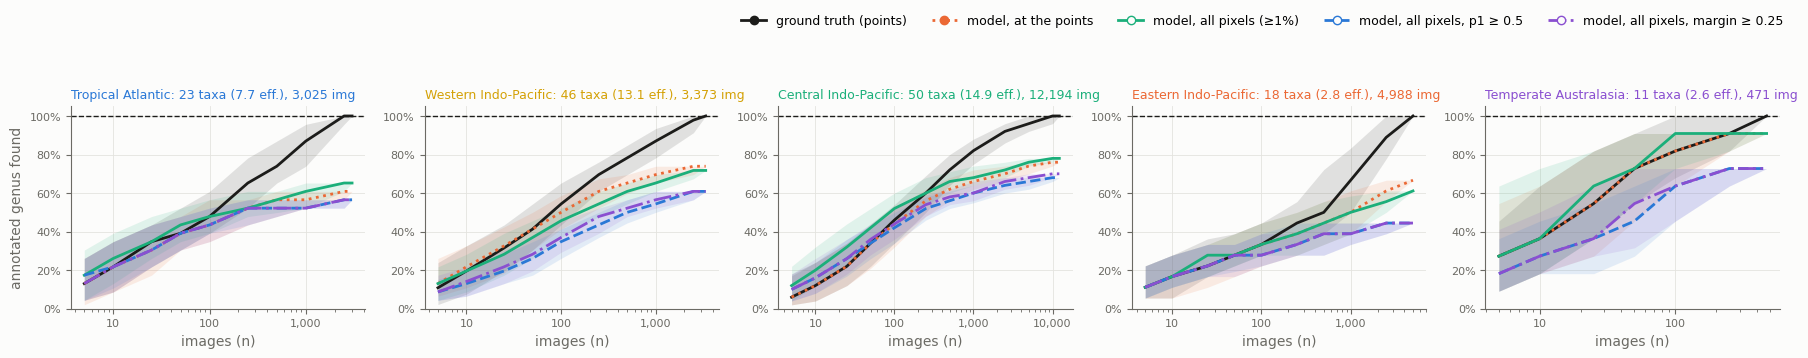

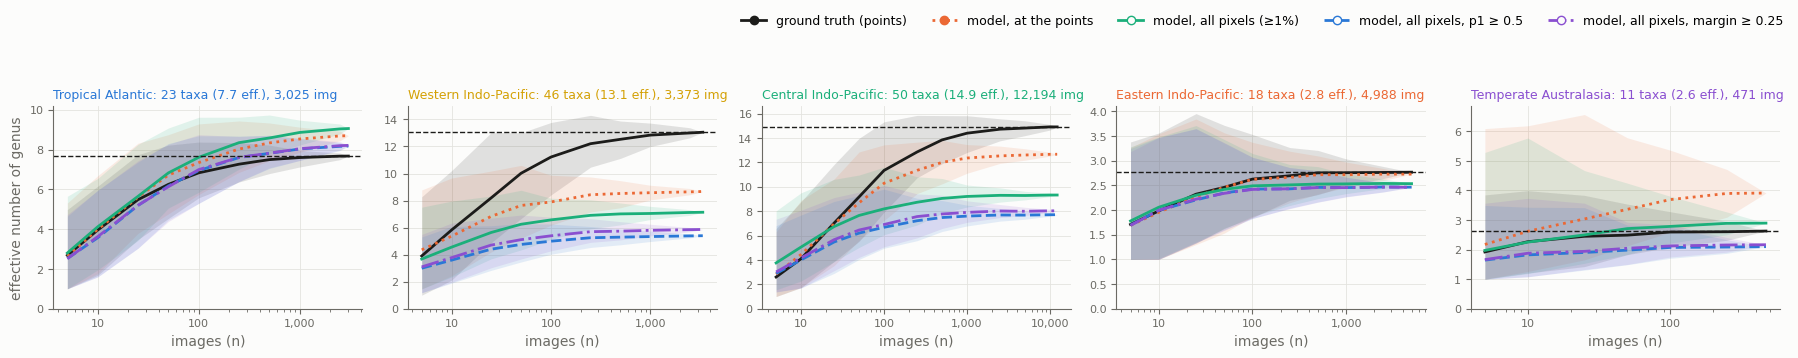

In [7]:
display(show_summary(S_GENUS["region"], "genus"))
ratio_plot(S_GENUS["region"], "genus", "Per region, images pooled")
ACC_GENUS_REG = {g: accumulation("genus", rows) for g, rows in ROWS["genus"]["region"].items()}
HILL_GENUS_REG = {g: hill_curve("genus", rows) for g, rows in ROWS["genus"]["region"].items()}
n_reg = len(ROWS["genus"]["region"])
grid_plot(ACC_GENUS_REG, S_GENUS["region"], "genus", "region", "rich", ncols=n_reg)
grid_plot(ACC_GENUS_REG, S_GENUS["region"], "genus", "region", "recall", ncols=n_reg)
grid_plot(HILL_GENUS_REG, S_GENUS["region"], "genus", "region", "hill", ncols=n_reg)

### 2.3 All test data (all eligible sources pooled)
Richness and recall accumulation, and the effective number from n random images.

sources images              richness                                                                                                                       effective                                               ...  \
                        ground truth (points) model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 ground truth (points) model, at the points model, all pixels (≥1%)  ...   
genus                                                                                                                                                                                                                       ...   
all test      18  24051                    76                   54                      53                          46                               47     12.3 [11.9, 12.7]      9.7 [9.5, 10.0]          9.2 [8.9, 9.4]  ...   

                           precision                                                recall                                                                                      composition similarity                          \
         model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25   model, at the points model, all pixels (≥1%)   
genus                                                                                                                                                                                                                            
all test                        0.98                             0.98                 0.67                    0.67                        0.59                             0.61                   0.89                    0.87   

                                                                       
         model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25  
genus                                                                  
all test                        0.84                             0.85  

[1 rows x 24 columns]

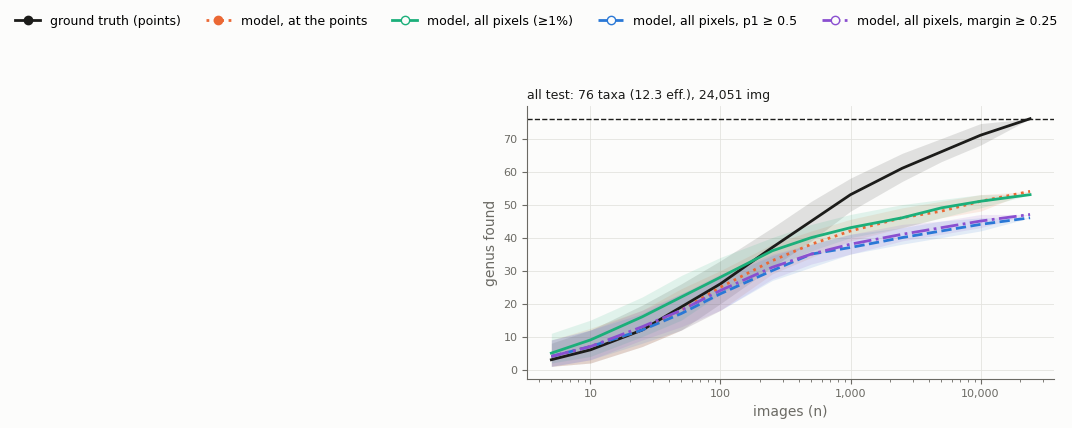

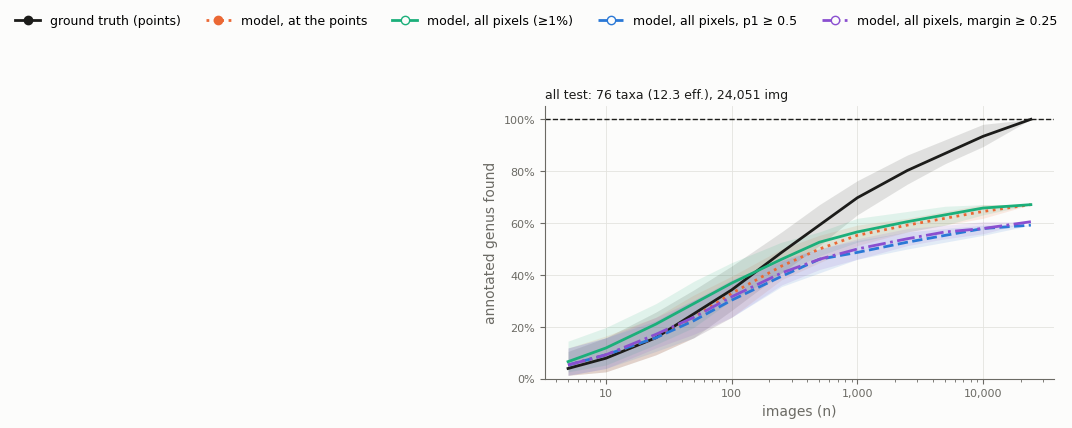

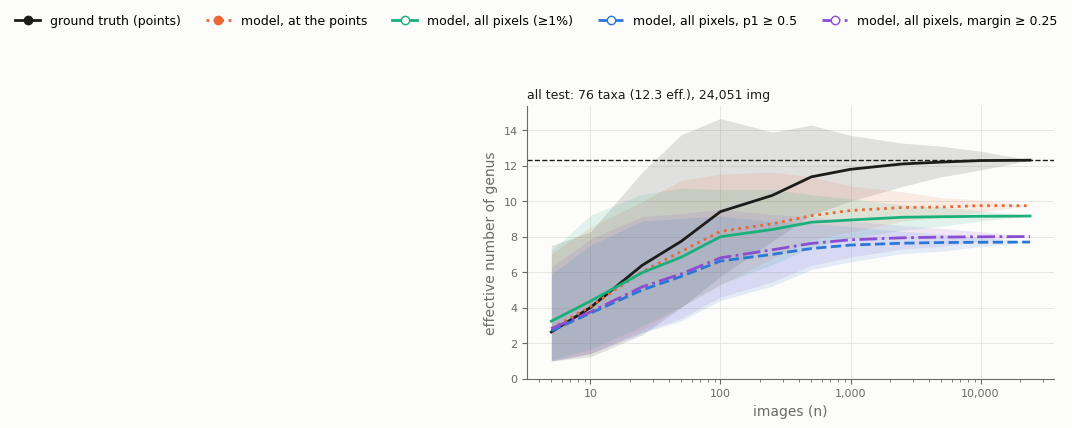

In [8]:
display(show_summary(S_GENUS["all"], "genus"))
rows_all = ROWS["genus"]["all"]["all test"]
ACC_GENUS_ALL = {"all test": accumulation("genus", rows_all)}
HILL_GENUS_ALL = {"all test": hill_curve("genus", rows_all)}
for kind in ("rich", "recall", "hill"):
    grid_plot(ACC_GENUS_ALL if kind != "hill" else HILL_GENUS_ALL, S_GENUS["all"], "genus", "all",
              kind, ncols=1, panel=(6, 3.6))

Which genus make up the pooled test set, and how the model's relative abundance compares (top 15 by annotated points;
model at the points and all pixels as shares of their own totals).

In [9]:
rows_all = ROWS["genus"]["all"]["all test"]
comp = pd.DataFrame({ESTIMATES[k][0]: abundance("genus", rows_all, k).sum(axis=0) for k in ESTIMATES},
                    index=TAXA["genus"])
comp = comp / comp.sum()
comp["images with it (GT)"] = (abundance("genus", rows_all, "truth") > 0).sum(axis=0)
comp["images with it (pixels)"] = (abundance("genus", rows_all, "model_dense") > 0).sum(axis=0)
comp = comp.sort_values(ESTIMATES["truth"][0], ascending=False)
top = comp.head(15)
missing = comp[(comp[ESTIMATES["truth"][0]] > 0) & (comp[ESTIMATES["model_dense"][0]] == 0)]
false = comp[(comp[ESTIMATES["truth"][0]] == 0) & (comp[ESTIMATES["model_dense"][0]] > 0)]
print(f"annotated genus never predicted (all pixels): {len(missing)}: " + ", ".join(missing.index[:20]))
print(f"predicted genus never annotated (all pixels): {len(false)}: "
      + ", ".join(f"{t} ({v:.2%})" for t, v in false[ESTIMATES["model_dense"][0]].sort_values(ascending=False).head(10).items()))
top.style.format({c: "{:.1%}" for c in top.columns if "images" not in c})

annotated genus never predicted (all pixels): 25: alveopora, gyrosmilia, gardineroseris, pectinia, oxypora, ctenactis, plesiastrea, mycetophyllia, tubastraea, oulophyllia, herpolitha, solenastrea, caulastraea, blastomussa, podabacia, sandalolitha, lobactis, manicina, sclerophyllia, isophyllia
predicted genus never annotated (all pixels): 2: fimbriaphyllia (0.00%), mussismilia (0.00%)


,ground truth (points),"model, at the points","model, all pixels (≥1%)","model, all pixels, p1 ≥ 0.5","model, all pixels, margin ≥ 0.25",images with it (GT),images with it (pixels)
porites,40.1%,40.7%,45.7%,49.4%,48.5%,6972,12231
acropora,10.5%,11.2%,9.1%,10.1%,9.9%,1554,2492
montipora,8.5%,12.5%,10.9%,9.3%,9.4%,1743,4453
pocillopora,6.8%,9.8%,7.4%,8.1%,7.9%,1584,3322
echinopora,3.2%,1.4%,1.0%,0.6%,0.8%,609,392
goniastrea,2.8%,2.2%,2.2%,1.8%,1.9%,1102,1906
galaxea,2.7%,3.0%,2.2%,2.0%,2.1%,655,1113
orbicella,2.3%,2.0%,2.1%,2.2%,2.2%,476,613
agaricia,2.0%,1.5%,1.2%,1.3%,1.3%,509,592
goniopora,1.6%,1.3%,0.9%,0.6%,0.7%,518,430


Ground truth vs model relative abundance per genus, all test data pooled (log axes; dashed: 1:1, band: within 2×).
Marker area ∝ the number of images in which the genus is annotated. Annotated genera the model never predicts sit on the
bottom edge (open markers). Labelled: the 15 most abundant genera in the annotations and every genus off by more than 3×.

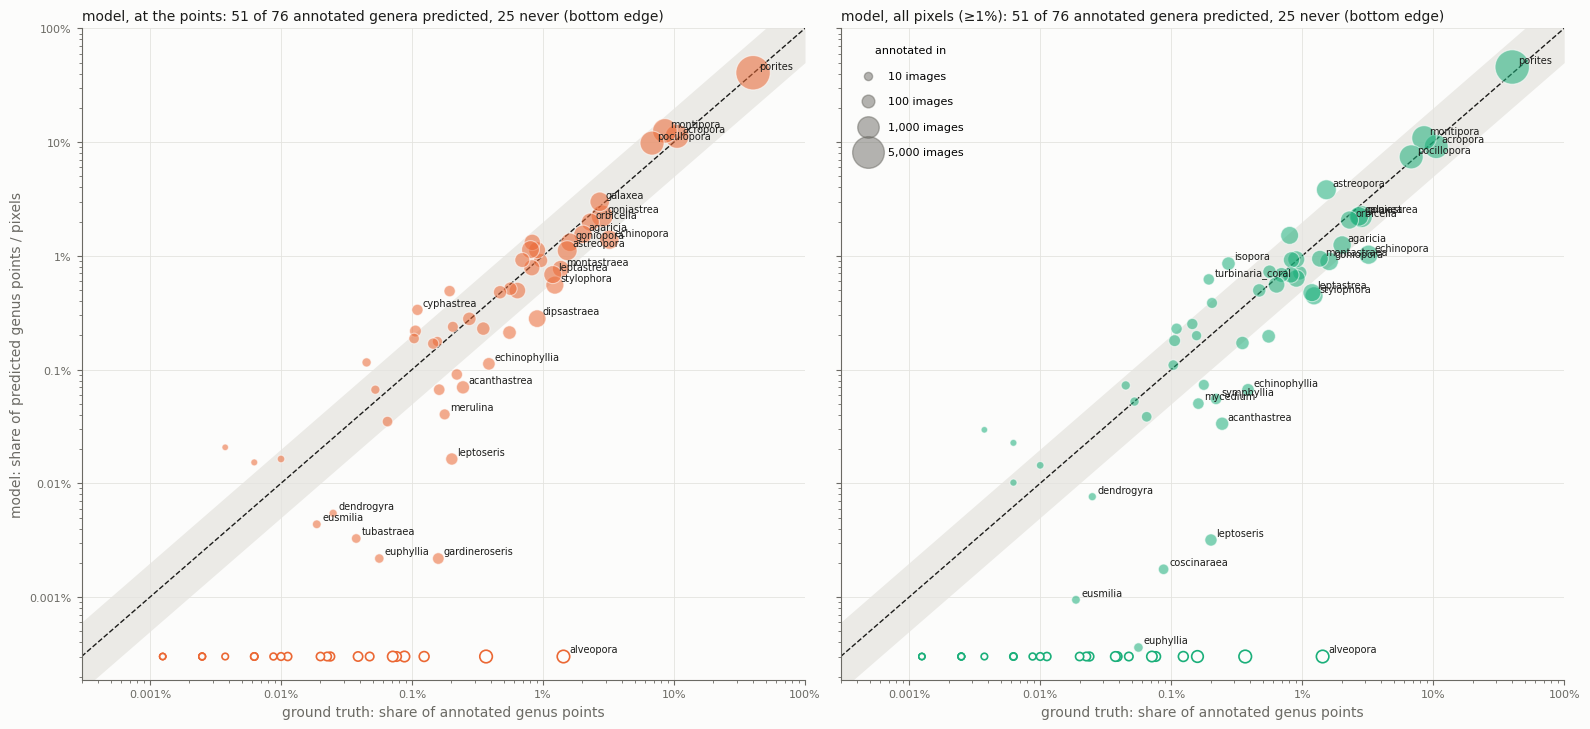

all pixels: 30 of 76 annotated genera within 2×; over 2×: 6, under 0.5× (incl. never predicted): 40


In [10]:
LVL, PL = "genus", "genera"
FLOOR = 3e-6  # where zero model abundance is drawn
pct_fmt = mticker.FuncFormatter(lambda v, _: f"{100 * v:.3g}%")
c = comp[comp[ESTIMATES["truth"][0]] > 0]  # annotated taxa (log x axis)
gt = c[ESTIMATES["truth"][0]]
n_img = c["images with it (GT)"]
size = 12 + 600 * np.sqrt(n_img / n_img.max())
fig, axes = plt.subplots(1, 2, figsize=(16, 7.4), sharex=True, sharey=True)
for ax, key in zip(axes, ("model_points", "model_dense")):
    label, color, _, _ = ESTIMATES[key]
    m = c[label]
    zero = m == 0
    ax.fill_between([FLOOR, 1], [FLOOR / 2, 0.5], [FLOOR * 2, 2], color=BAND, lw=0, zorder=0)
    ax.plot([FLOOR, 1], [FLOOR, 1], color=INK, lw=1, ls="--", zorder=1)
    ax.scatter(gt[~zero], m[~zero], s=size[~zero], color=color, alpha=0.55, edgecolor="white", lw=0.8, zorder=3)
    ax.scatter(gt[zero], np.full(zero.sum(), FLOOR), s=size[zero], facecolor=SURFACE, edgecolor=color, lw=1.2, zorder=3)
    ratio = m / gt
    lab = set(gt.nlargest(15).index) | set(c.index[~zero & ((ratio > 3) | (ratio < 1 / 3)) & (gt > 1e-4)])
    for t in lab:
        ax.annotate(t, (gt[t], m[t] if m[t] > 0 else FLOOR), xytext=(4, 3), textcoords="offset points", fontsize=7,
                    color=INK)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(FLOOR, 1)
    ax.set_ylim(FLOOR / 1.6, 1)
    ax.xaxis.set_major_formatter(pct_fmt)
    ax.yaxis.set_major_formatter(pct_fmt)
    ax.set_xlabel(f"ground truth: share of annotated {LVL} points")
    ax.set_title(f"{label}: {int((~zero).sum())} of {len(c)} annotated {PL} predicted, {int(zero.sum())} never (bottom edge)")
axes[0].set_ylabel(f"model: share of predicted {LVL} points / pixels")
for n in (10, 100, 1000, 5000):
    axes[1].scatter([], [], s=12 + 600 * np.sqrt(n / n_img.max()), color=MUTED, alpha=0.5, label=f"{n:,} images")
axes[1].legend(title="annotated in", fontsize=8, title_fontsize=8, loc="upper left", labelspacing=1.4, borderpad=1)
fig.tight_layout()
plt.show()
r = c[ESTIMATES["model_dense"][0]] / gt
print(f"all pixels: {int(r.between(0.5, 2).sum())} of {len(c)} annotated {PL} within 2×; "
      f"over 2×: {int((r > 2).sum())}, under 0.5× (incl. never predicted): {int((r < 0.5).sum())}")

Model bias per genus against how common it is in the annotations (all test data pooled): (a) the number of images in
which the genus is annotated, (b) the number of annotated points of the genus. Top row: relative bias, model share /
annotated share (log; 1 = unbiased, never-predicted genera on the bottom edge). Bottom row: absolute bias, model share −
annotated share (percentage points of all genus points / pixels). Orange: at the points; green: all pixels.

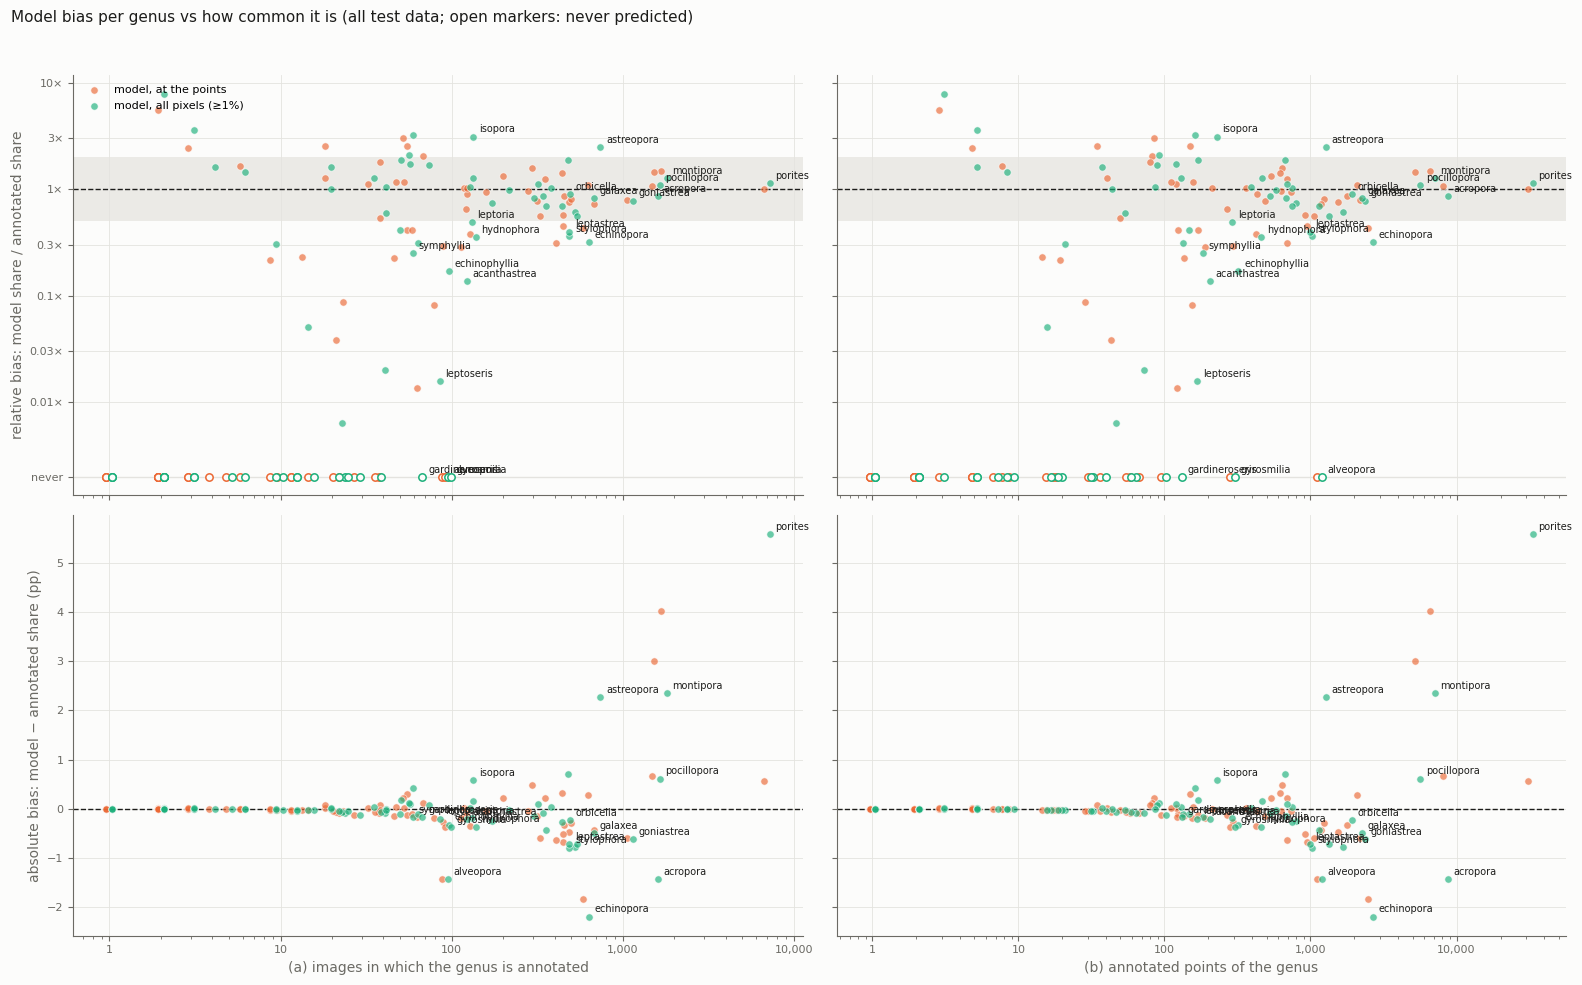

In [11]:
LVL, PL = "genus", "genera"
FLOOR_R = 0.002  # where a relative bias of 0 (never predicted) is drawn
c = comp[comp[ESTIMATES["truth"][0]] > 0].copy()
c["annotated points"] = pd.Series(abundance(LVL, rows_all, "truth").sum(axis=0), index=TAXA[LVL])[c.index]
gt = c[ESTIMATES["truth"][0]]
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex="col", sharey="row")
for j, (xcol, xlabel) in enumerate((("images with it (GT)", f"(a) images in which the {LVL} is annotated"),
                                    ("annotated points", f"(b) annotated points of the {LVL}"))):
    x = c[xcol]
    for key, dx in (("model_points", 0.96), ("model_dense", 1.04)):  # small offset so the two estimates don't overlap
        label, color, _, _ = ESTIMATES[key]
        m = c[label]
        rel = (m / gt).where(m > 0, FLOOR_R)
        zero = m == 0
        ax = axes[0, j]
        ax.scatter(x[~zero] * dx, rel[~zero], s=28, color=color, alpha=0.65, edgecolor="white", lw=0.6, zorder=3, label=label)
        ax.scatter(x[zero] * dx, rel[zero], s=28, facecolor=SURFACE, edgecolor=color, lw=1.1, zorder=3)
        ax = axes[1, j]
        ax.scatter(x * dx, 100 * (m - gt), s=28, color=color, alpha=0.65, edgecolor="white", lw=0.6, zorder=3)
    for ax in axes[:, j]:
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    axes[1, j].set_xlabel(xlabel)
    # Label the most common taxa and the most biased ones.
    rel_d = c[ESTIMATES["model_dense"][0]] / gt
    never = rel_d.index[rel_d == 0]
    lab = (set(gt.nlargest(8).index) | set(rel_d[(gt > 2e-3) & (rel_d > 0)].pipe(lambda s: s[(s > 2) | (s < 0.5)]).index)
           | set(gt[never].nlargest(3).index))  # never predicted: only the 3 most annotated
    for t in lab:
        md_ = c.loc[t, ESTIMATES["model_dense"][0]]
        axes[0, j].annotate(t, (c.loc[t, xcol] * 1.04, md_ / gt[t] if md_ > 0 else FLOOR_R), xytext=(4, 3),
                            textcoords="offset points", fontsize=7, color=INK)
        axes[1, j].annotate(t, (c.loc[t, xcol] * 1.04, 100 * (md_ - gt[t])), xytext=(4, 3), textcoords="offset points",
                            fontsize=7, color=INK)
ax = axes[0, 0]
ax.set_yscale("log")
ax.set_ylim(FLOOR_R / 1.5, max(10, 1.5 * (c[ESTIMATES["model_dense"][0]] / gt).max()))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: "never" if abs(v - FLOOR_R) < 1e-9 else f"{v:g}×"))
ax.set_yticks([FLOOR_R, 0.01, 0.03, 0.1, 0.3, 1, 3, 10])
ax.yaxis.set_minor_locator(mticker.NullLocator())
ax.set_ylabel("relative bias: model share / annotated share")
axes[1, 0].set_ylabel("absolute bias: model − annotated share (pp)")
for ax in axes[0]:
    ax.axhspan(0.5, 2, color=BAND, lw=0, zorder=0)
    ax.axhline(1, color=INK, lw=1, ls="--")
    ax.axhline(FLOOR_R, color=GRID, lw=1)
for ax in axes[1]:
    ax.axhline(0, color=INK, lw=1, ls="--")
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Model bias per {LVL} vs how common it is (all test data; open markers: never predicted)", x=0.01,
             ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## 3. Families
### 3.1 Per source
From all of a source's images: richness, effective number (95% bootstrap CI), family-list precision and recall, and
composition similarity. Sources grouped by region (marker colour in the figure).

images              richness                                                                                                                       effective                                                                           \
              ground truth (points) model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 ground truth (points) model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5   
family                                                                                                                                                                                                                                         
4091      463                    10                   10                      10                          10                               10        5.1 [4.8, 5.4]       5.3 [5.0, 5.5]          5.0 [4.7, 5.2]              5.0 [4.7, 5.2]   
5181     1061                    11                   13                      13                          11                               11        6.6 [6.1, 6.9]       6.4 [5.8, 6.8]          6.0 [5.6, 6.4]              5.9 [5.4, 6.3]   
6494      133                     9                    8                       8                           8                                8        4.7 [3.8, 5.5]       4.6 [3.3, 5.5]          4.2 [3.1, 5.2]              4.2 [3.0, 5.1]   
6702     1368                    11                   17                      17                          15                               16        5.7 [5.3, 6.0]       6.4 [5.9, 6.8]          6.1 [5.7, 6.5]              5.8 [5.4, 6.1]   
4721     2909                    13                   19                      18                          17                               17        4.8 [4.6, 5.0]       4.4 [4.3, 4.6]          4.2 [4.1, 4.3]              4.0 [3.8, 4.1]   
4342      464                    14                   14                      13                          10                               10        4.5 [4.2, 4.7]       5.4 [5.1, 5.6]          4.9 [4.6, 5.2]              4.2 [3.9, 4.5]   
1776      447                     5                   12                      13                          13                               13        1.9 [1.7, 2.1]       2.3 [2.1, 2.6]          2.1 [1.9, 2.4]              2.0 [1.8, 2.2]   
3606     2185                    13                   15                      15                          14                               14        6.1 [5.9, 6.3]       5.5 [5.3, 5.7]          5.3 [5.1, 5.5]              5.3 [5.1, 5.5]   
4957     9012                    16                   17                      18                          18                               18        4.3 [4.2, 4.5]       4.3 [4.2, 4.5]          4.2 [4.0, 4.3]              4.0 [3.9, 4.1]   
7116      770                     8                   12                      12                          10                               10        5.7 [5.5, 5.8]       6.8 [6.5, 7.1]          3.8 [3.5, 4.0]              3.6 [3.3, 3.8]   
1990     1233                     4                    7                       7                           7                                7        1.9 [1.8, 2.0]       1.8 [1.7, 1.9]          1.8 [1.7, 1.9]              1.7 [1.7, 1.8]   
2682      675                     5                    7                       7                           6                                6        2.4 [2.2, 2.5]       2.2 [2.1, 2.4]          2.2 [2.0, 2.4]              2.1 [1.9, 2.2]   
3357      564                     6                    5                       7                           6                                6        2.3 [2.1, 2.4]       2.1 [1.9, 2.3]          2.1 [2.0, 2.3]              2.1 [1.9, 2.2]   
6405     1332                     5                    5                       7                           6                                7        2.5 [2.3, 2.7]    

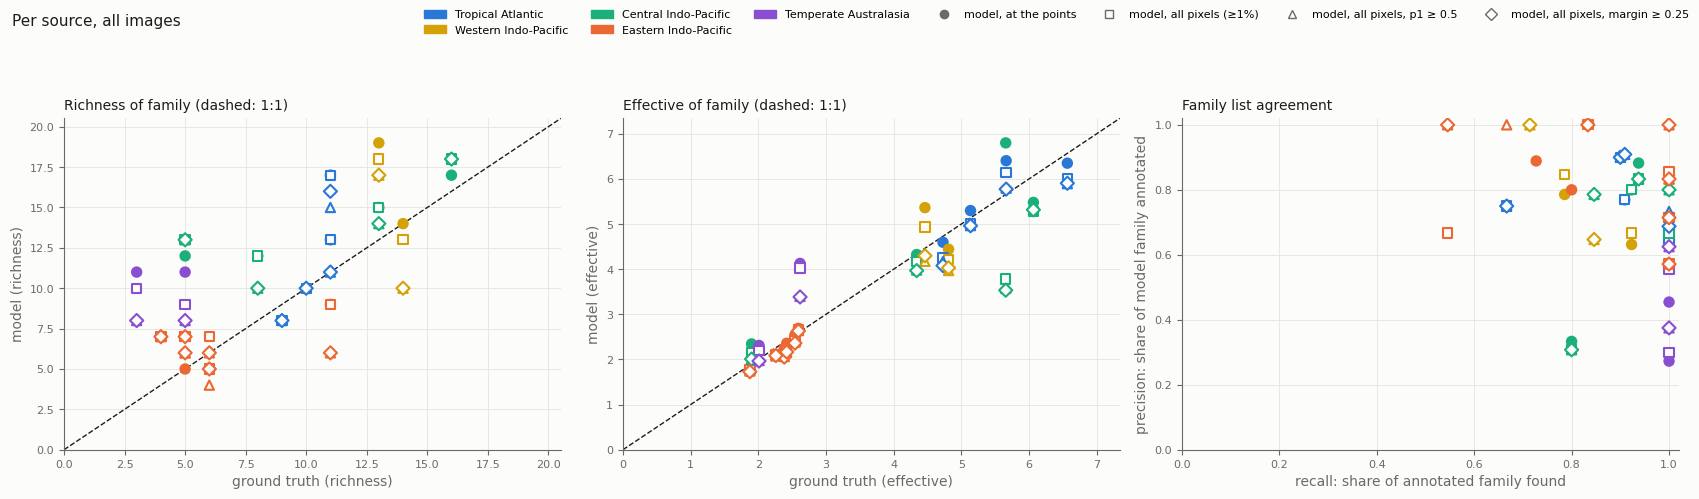

In [12]:
S_FAMILY = {scope: summarize("family", scope) for scope in ("source", "region", "all")}
display(show_summary(S_FAMILY["source"], "family"))
ratio_plot(S_FAMILY["source"], "family", "Per source, all images")

Accumulation per source: family found after n random images (median, 95% band over `R` random orders; dashed: annotated
family, all images).

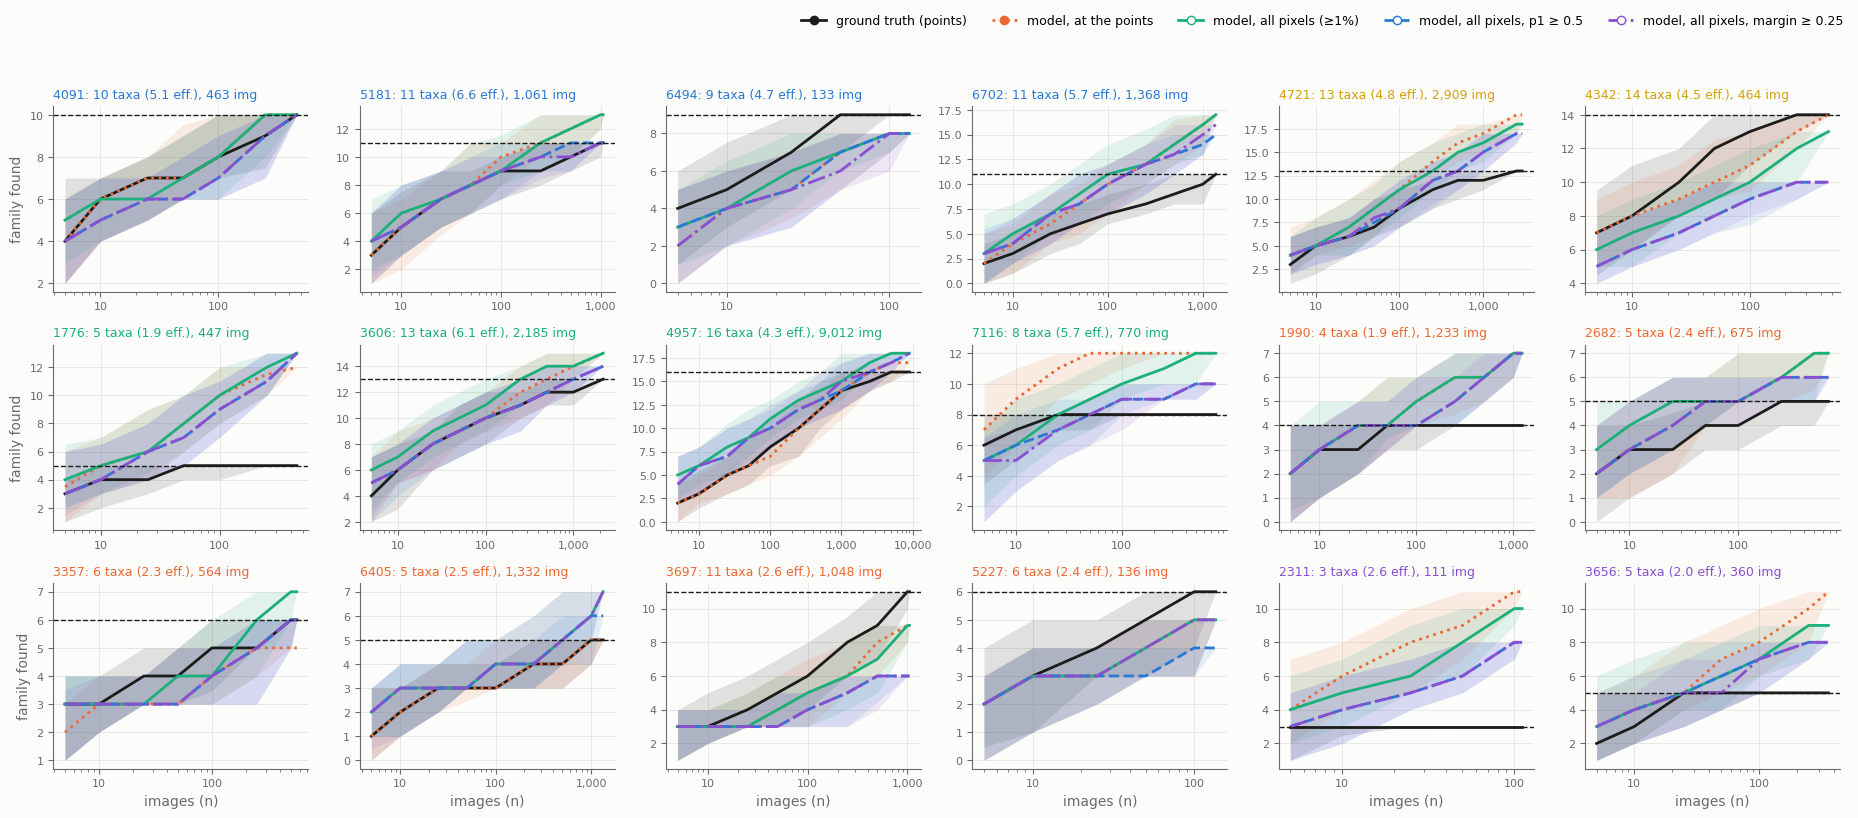

In [13]:
ACC_FAMILY_SRC = {g: accumulation("family", rows) for g, rows in ROWS["family"]["source"].items()}
grid_plot(ACC_FAMILY_SRC, S_FAMILY["source"], "family", "source", "rich", ncols=6, panel=(3.1, 2.5))

### 3.2 Per region (images pooled across the region's sources)

sources images              richness                                                                                                                       effective                                               ...  \
                                     ground truth (points) model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 ground truth (points) model, at the points model, all pixels (≥1%)  ...   
family                                                                                                                                                                                                                                   ...   
Tropical Atlantic           4   3025                    12                   18                      18                          15                               16        6.7 [6.5, 6.9]       6.9 [6.6, 7.1]          6.8 [6.6, 7.1]  ...   
Western Indo-Pacific        2   3373                    15                   19                      18                          17                               17        5.6 [5.4, 5.7]       5.2 [5.0, 5.3]          4.8 [4.6, 4.9]  ...   
Central Indo-Pacific        4  12414                    18                   17                      18                          18                               18        6.1 [6.0, 6.3]       5.8 [5.6, 5.9]          4.9 [4.8, 5.0]  ...   
Eastern Indo-Pacific        6   4988                    11                    9                      10                           7                                7        2.4 [2.4, 2.5]       2.4 [2.3, 2.5]          2.3 [2.2, 2.4]  ...   
Temperate Australasia       2    471                     5                   13                      12                          10                               10        2.4 [2.2, 2.7]       3.1 [2.7, 3.6]          2.5 [2.2, 2.8]  ...   

                                        precision                                                recall                                                                                      composition similarity                          \
                      model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25   model, at the points model, all pixels (≥1%)   
family                                                                                                                                                                                                                                        
Tropical Atlantic                            0.73                             0.69                 1.00                    1.00                        0.92                             0.92                   0.93                    0.89   
Western Indo-Pacific                         0.76                             0.76                 0.93                    0.93                        0.87                             0.87                   0.84                    0.80   
Central Indo-Pacific                         0.89                             0.89                 0.89                    0.89                        0.89                             0.89                   0.87                    0.86   
Eastern Indo-Pacific                         1.00                             1.00                 0.73                    0.64                        0.64                             0.64                   0.98                    0.98   
Temperate Australasia                        0.50                             0.50                 1.00                    1.00                        1.00                             1.00                   0.88                    0.92   

                                                                                    
                      model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25  
family            

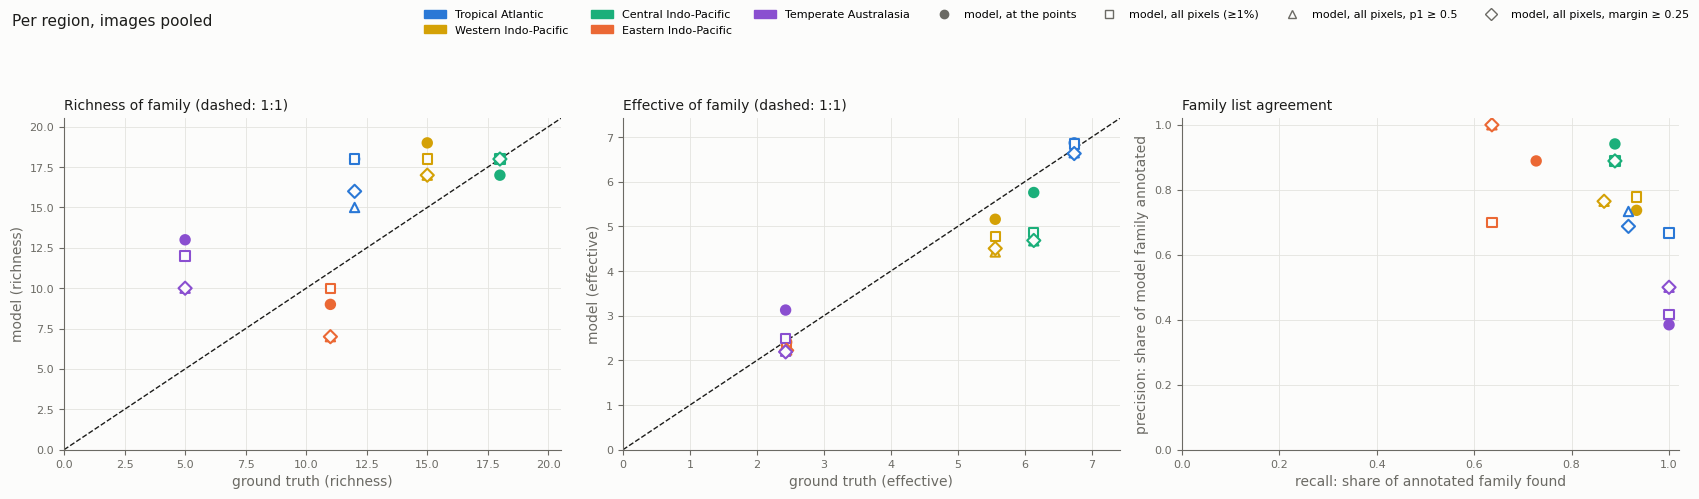

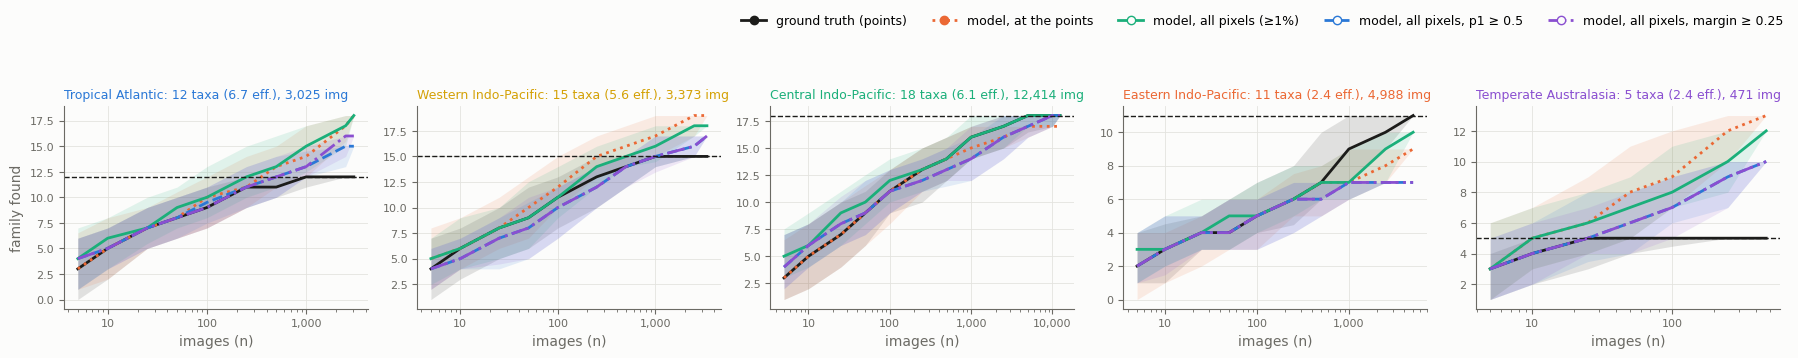

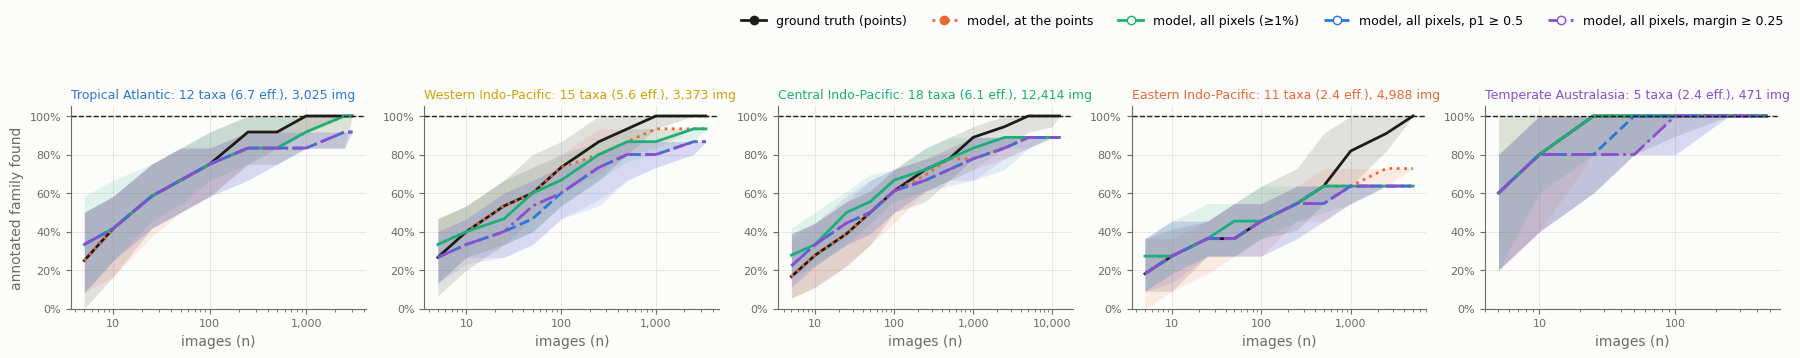

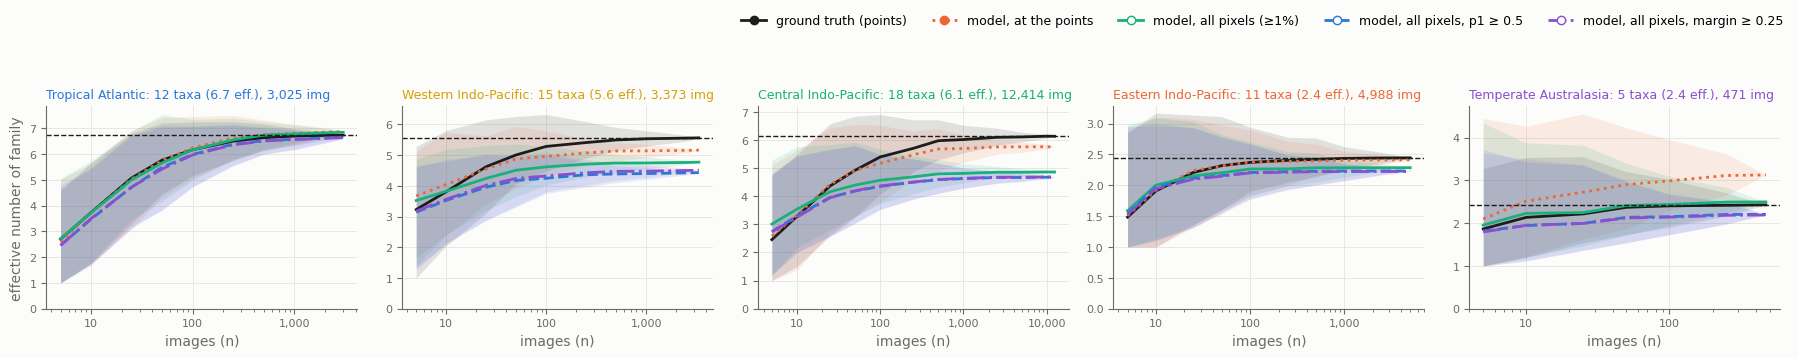

In [14]:
display(show_summary(S_FAMILY["region"], "family"))
ratio_plot(S_FAMILY["region"], "family", "Per region, images pooled")
ACC_FAMILY_REG = {g: accumulation("family", rows) for g, rows in ROWS["family"]["region"].items()}
HILL_FAMILY_REG = {g: hill_curve("family", rows) for g, rows in ROWS["family"]["region"].items()}
n_reg = len(ROWS["family"]["region"])
grid_plot(ACC_FAMILY_REG, S_FAMILY["region"], "family", "region", "rich", ncols=n_reg)
grid_plot(ACC_FAMILY_REG, S_FAMILY["region"], "family", "region", "recall", ncols=n_reg)
grid_plot(HILL_FAMILY_REG, S_FAMILY["region"], "family", "region", "hill", ncols=n_reg)

### 3.3 All test data (all eligible sources pooled)
Richness and recall accumulation, and the effective number from n random images.

sources images              richness                                                                                                                       effective                                               ...  \
                        ground truth (points) model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 ground truth (points) model, at the points model, all pixels (≥1%)  ...   
family                                                                                                                                                                                                                      ...   
all test      18  24271                    21                   19                      19                          19                               19        5.9 [5.7, 6.0]       5.5 [5.4, 5.6]          5.1 [5.0, 5.2]  ...   

                           precision                                                recall                                                                                      composition similarity                          \
         model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 model, at the points model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25   model, at the points model, all pixels (≥1%)   
family                                                                                                                                                                                                                           
all test                         1.0                              1.0                  0.9                     0.9                         0.9                              0.9                   0.95                    0.94   

                                                                       
         model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25  
family                                                                 
all test                        0.93                             0.93  

[1 rows x 24 columns]

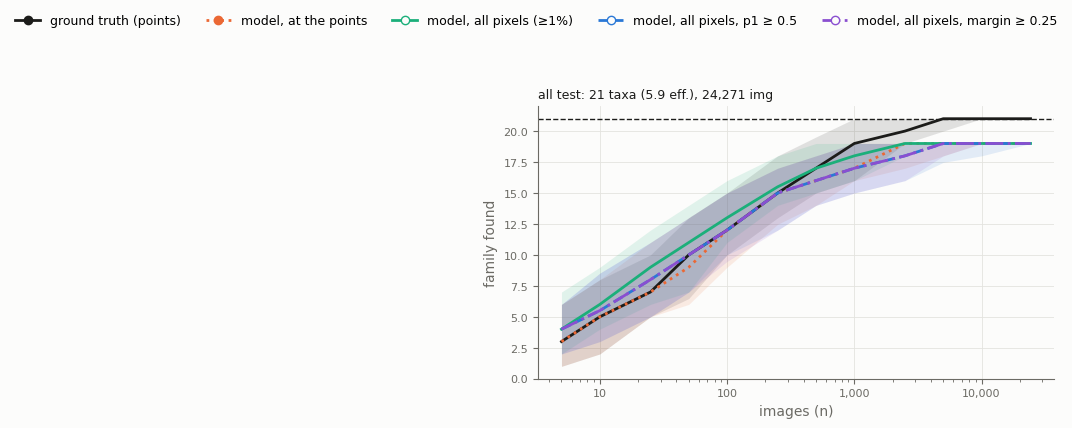

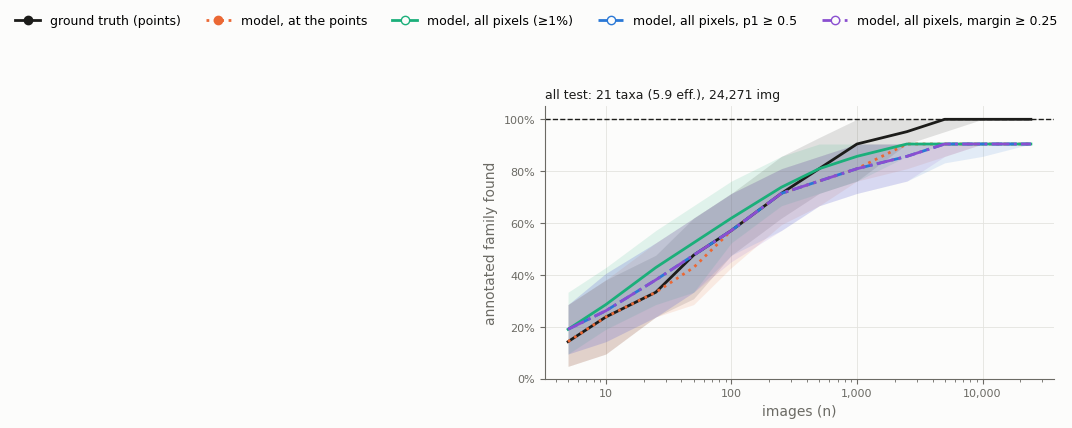

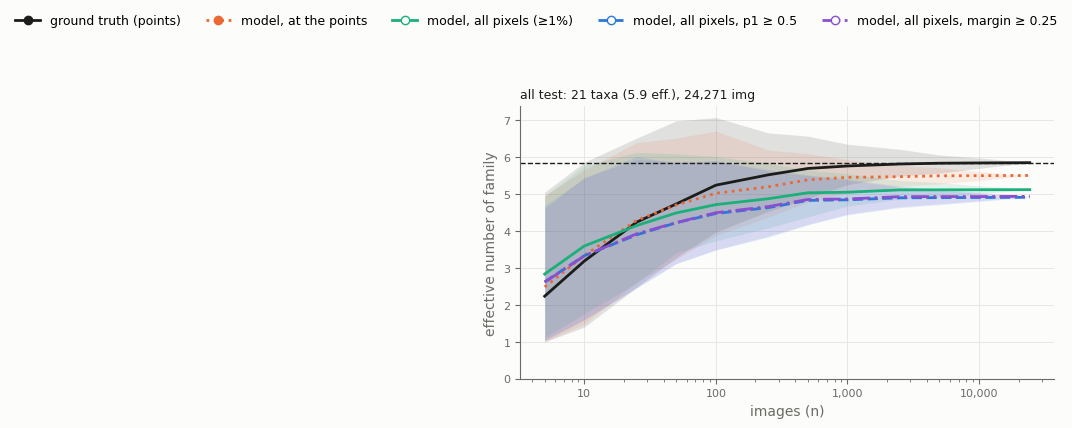

In [15]:
display(show_summary(S_FAMILY["all"], "family"))
rows_all = ROWS["family"]["all"]["all test"]
ACC_FAMILY_ALL = {"all test": accumulation("family", rows_all)}
HILL_FAMILY_ALL = {"all test": hill_curve("family", rows_all)}
for kind in ("rich", "recall", "hill"):
    grid_plot(ACC_FAMILY_ALL if kind != "hill" else HILL_FAMILY_ALL, S_FAMILY["all"], "family", "all",
              kind, ncols=1, panel=(6, 3.6))

Which family make up the pooled test set, and how the model's relative abundance compares (every family annotated or predicted, by annotated points;
model at the points and all pixels as shares of their own totals).

In [16]:
rows_all = ROWS["family"]["all"]["all test"]
comp = pd.DataFrame({ESTIMATES[k][0]: abundance("family", rows_all, k).sum(axis=0) for k in ESTIMATES},
                    index=TAXA["family"])
comp = comp / comp.sum()
comp["images with it (GT)"] = (abundance("family", rows_all, "truth") > 0).sum(axis=0)
comp["images with it (pixels)"] = (abundance("family", rows_all, "model_dense") > 0).sum(axis=0)
comp = comp.sort_values(ESTIMATES["truth"][0], ascending=False)
top = comp[(comp.iloc[:, :3] > 0).any(axis=1)]
missing = comp[(comp[ESTIMATES["truth"][0]] > 0) & (comp[ESTIMATES["model_dense"][0]] == 0)]
false = comp[(comp[ESTIMATES["truth"][0]] == 0) & (comp[ESTIMATES["model_dense"][0]] > 0)]
print(f"annotated family never predicted (all pixels): {len(missing)}: " + ", ".join(missing.index[:20]))
print(f"predicted family never annotated (all pixels): {len(false)}: "
      + ", ".join(f"{t} ({v:.2%})" for t, v in false[ESTIMATES["model_dense"][0]].sort_values(ascending=False).head(10).items()))
top.style.format({c: "{:.1%}" for c in top.columns if "images" not in c})

annotated family never predicted (all pixels): 2: coscinaraeidae, plesiastreidae
predicted family never annotated (all pixels): 0: 


,ground truth (points),"model, at the points","model, all pixels (≥1%)","model, all pixels, p1 ≥ 0.5","model, all pixels, margin ≥ 0.25",images with it (GT),images with it (pixels)
poritidae,40.5%,39.7%,44.6%,46.5%,46.3%,7352,12329
acroporidae,24.6%,26.9%,25.6%,25.2%,25.1%,4003,7896
merulinidae,12.2%,10.7%,10.8%,9.5%,9.8%,2990,6204
pocilloporidae,7.9%,10.4%,7.8%,8.2%,8.1%,1946,3909
agariciidae,4.0%,3.7%,3.4%,3.2%,3.2%,1243,2745
euphylliidae,3.0%,2.9%,2.2%,2.0%,2.1%,764,1102
lobophylliidae,1.6%,1.2%,0.9%,0.8%,0.8%,487,544
montastraeidae,1.3%,0.7%,0.9%,0.9%,0.9%,342,278
mussidae,1.2%,1.2%,1.3%,1.4%,1.4%,352,463
leptastreidae,1.1%,0.5%,0.4%,0.3%,0.3%,470,537


Ground truth vs model relative abundance per family, all test data pooled (log axes; dashed: 1:1, band: within 2×).
Marker area ∝ the number of images in which the family is annotated. Annotated families the model never predicts sit on the
bottom edge (open markers). Labelled: the 15 most abundant families in the annotations and every family off by more than 3×.

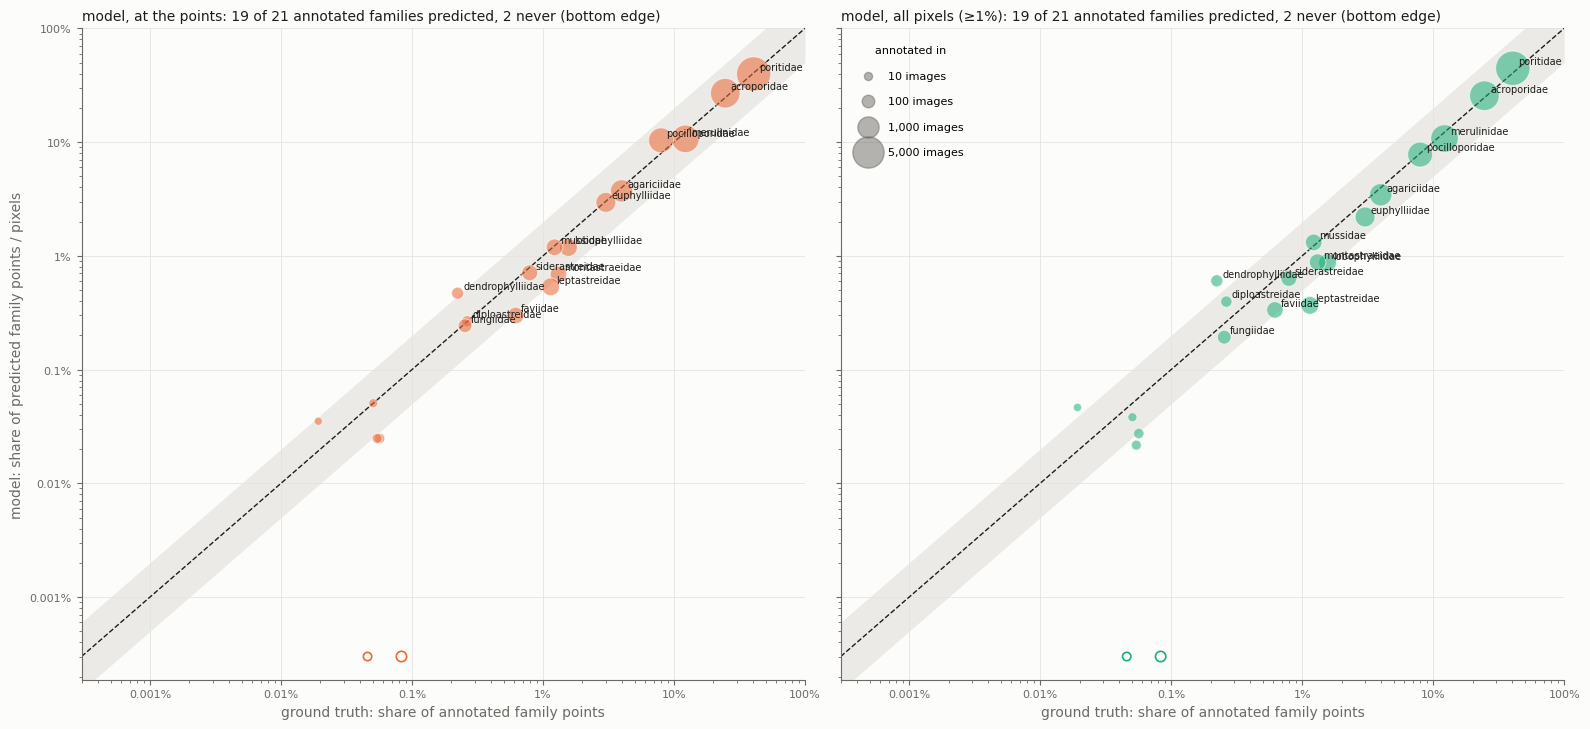

all pixels: 14 of 21 annotated families within 2×; over 2×: 2, under 0.5× (incl. never predicted): 5


In [17]:
LVL, PL = "family", "families"
FLOOR = 3e-6  # where zero model abundance is drawn
pct_fmt = mticker.FuncFormatter(lambda v, _: f"{100 * v:.3g}%")
c = comp[comp[ESTIMATES["truth"][0]] > 0]  # annotated taxa (log x axis)
gt = c[ESTIMATES["truth"][0]]
n_img = c["images with it (GT)"]
size = 12 + 600 * np.sqrt(n_img / n_img.max())
fig, axes = plt.subplots(1, 2, figsize=(16, 7.4), sharex=True, sharey=True)
for ax, key in zip(axes, ("model_points", "model_dense")):
    label, color, _, _ = ESTIMATES[key]
    m = c[label]
    zero = m == 0
    ax.fill_between([FLOOR, 1], [FLOOR / 2, 0.5], [FLOOR * 2, 2], color=BAND, lw=0, zorder=0)
    ax.plot([FLOOR, 1], [FLOOR, 1], color=INK, lw=1, ls="--", zorder=1)
    ax.scatter(gt[~zero], m[~zero], s=size[~zero], color=color, alpha=0.55, edgecolor="white", lw=0.8, zorder=3)
    ax.scatter(gt[zero], np.full(zero.sum(), FLOOR), s=size[zero], facecolor=SURFACE, edgecolor=color, lw=1.2, zorder=3)
    ratio = m / gt
    lab = set(gt.nlargest(15).index) | set(c.index[~zero & ((ratio > 3) | (ratio < 1 / 3)) & (gt > 1e-4)])
    for t in lab:
        ax.annotate(t, (gt[t], m[t] if m[t] > 0 else FLOOR), xytext=(4, 3), textcoords="offset points", fontsize=7,
                    color=INK)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(FLOOR, 1)
    ax.set_ylim(FLOOR / 1.6, 1)
    ax.xaxis.set_major_formatter(pct_fmt)
    ax.yaxis.set_major_formatter(pct_fmt)
    ax.set_xlabel(f"ground truth: share of annotated {LVL} points")
    ax.set_title(f"{label}: {int((~zero).sum())} of {len(c)} annotated {PL} predicted, {int(zero.sum())} never (bottom edge)")
axes[0].set_ylabel(f"model: share of predicted {LVL} points / pixels")
for n in (10, 100, 1000, 5000):
    axes[1].scatter([], [], s=12 + 600 * np.sqrt(n / n_img.max()), color=MUTED, alpha=0.5, label=f"{n:,} images")
axes[1].legend(title="annotated in", fontsize=8, title_fontsize=8, loc="upper left", labelspacing=1.4, borderpad=1)
fig.tight_layout()
plt.show()
r = c[ESTIMATES["model_dense"][0]] / gt
print(f"all pixels: {int(r.between(0.5, 2).sum())} of {len(c)} annotated {PL} within 2×; "
      f"over 2×: {int((r > 2).sum())}, under 0.5× (incl. never predicted): {int((r < 0.5).sum())}")

Model bias per family against how common it is in the annotations (all test data pooled): (a) the number of images in
which the family is annotated, (b) the number of annotated points of the family. Top row: relative bias, model share /
annotated share (log; 1 = unbiased, never-predicted families on the bottom edge). Bottom row: absolute bias, model share −
annotated share (percentage points of all family points / pixels). Orange: at the points; green: all pixels.

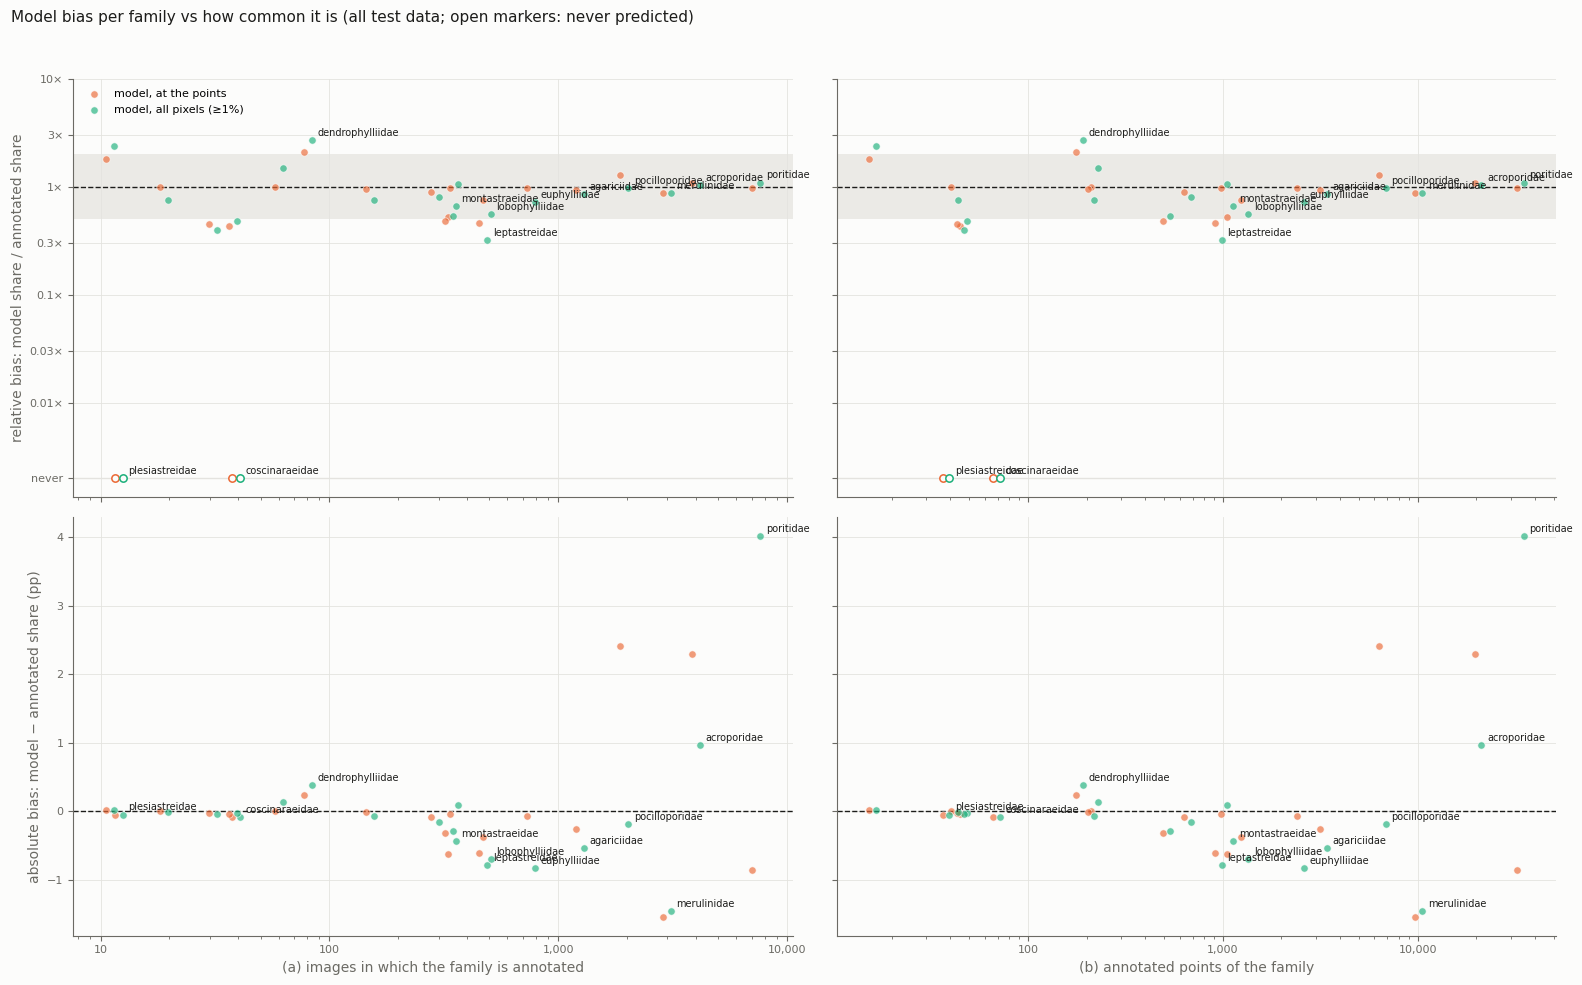

In [18]:
LVL, PL = "family", "families"
FLOOR_R = 0.002  # where a relative bias of 0 (never predicted) is drawn
c = comp[comp[ESTIMATES["truth"][0]] > 0].copy()
c["annotated points"] = pd.Series(abundance(LVL, rows_all, "truth").sum(axis=0), index=TAXA[LVL])[c.index]
gt = c[ESTIMATES["truth"][0]]
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex="col", sharey="row")
for j, (xcol, xlabel) in enumerate((("images with it (GT)", f"(a) images in which the {LVL} is annotated"),
                                    ("annotated points", f"(b) annotated points of the {LVL}"))):
    x = c[xcol]
    for key, dx in (("model_points", 0.96), ("model_dense", 1.04)):  # small offset so the two estimates don't overlap
        label, color, _, _ = ESTIMATES[key]
        m = c[label]
        rel = (m / gt).where(m > 0, FLOOR_R)
        zero = m == 0
        ax = axes[0, j]
        ax.scatter(x[~zero] * dx, rel[~zero], s=28, color=color, alpha=0.65, edgecolor="white", lw=0.6, zorder=3, label=label)
        ax.scatter(x[zero] * dx, rel[zero], s=28, facecolor=SURFACE, edgecolor=color, lw=1.1, zorder=3)
        ax = axes[1, j]
        ax.scatter(x * dx, 100 * (m - gt), s=28, color=color, alpha=0.65, edgecolor="white", lw=0.6, zorder=3)
    for ax in axes[:, j]:
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    axes[1, j].set_xlabel(xlabel)
    # Label the most common taxa and the most biased ones.
    rel_d = c[ESTIMATES["model_dense"][0]] / gt
    never = rel_d.index[rel_d == 0]
    lab = (set(gt.nlargest(8).index) | set(rel_d[(gt > 2e-3) & (rel_d > 0)].pipe(lambda s: s[(s > 2) | (s < 0.5)]).index)
           | set(gt[never].nlargest(3).index))  # never predicted: only the 3 most annotated
    for t in lab:
        md_ = c.loc[t, ESTIMATES["model_dense"][0]]
        axes[0, j].annotate(t, (c.loc[t, xcol] * 1.04, md_ / gt[t] if md_ > 0 else FLOOR_R), xytext=(4, 3),
                            textcoords="offset points", fontsize=7, color=INK)
        axes[1, j].annotate(t, (c.loc[t, xcol] * 1.04, 100 * (md_ - gt[t])), xytext=(4, 3), textcoords="offset points",
                            fontsize=7, color=INK)
ax = axes[0, 0]
ax.set_yscale("log")
ax.set_ylim(FLOOR_R / 1.5, max(10, 1.5 * (c[ESTIMATES["model_dense"][0]] / gt).max()))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: "never" if abs(v - FLOOR_R) < 1e-9 else f"{v:g}×"))
ax.set_yticks([FLOOR_R, 0.01, 0.03, 0.1, 0.3, 1, 3, 10])
ax.yaxis.set_minor_locator(mticker.NullLocator())
ax.set_ylabel("relative bias: model share / annotated share")
axes[1, 0].set_ylabel("absolute bias: model − annotated share (pp)")
for ax in axes[0]:
    ax.axhspan(0.5, 2, color=BAND, lw=0, zorder=0)
    ax.axhline(1, color=INK, lw=1, ls="--")
    ax.axhline(FLOOR_R, color=GRID, lw=1)
for ax in axes[1]:
    ax.axhline(0, color=INK, lw=1, ls="--")
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Model bias per {LVL} vs how common it is (all test data; open markers: never predicted)", x=0.01,
             ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## 4. Across scopes and levels
How close is the model to the annotations for one source, a region, or all test data, at genus and family level?
Ratios model / ground truth (1 = right), and list precision / recall. Per source: mean over sources (and range).

groups    richness ratio   effective ratio         precision            recall composition similarity
level  scope  estimate                                                                                                                               
genus  source model, at the points                  18  1.90 (0.75–9.33)  1.07 (0.74–2.11)  0.55 (0.11–0.77)  0.79 (0.50–1.00)       0.84 (0.64–0.97)
              model, all pixels (≥1%)               18  1.69 (0.62–6.33)  0.98 (0.49–1.98)  0.57 (0.16–0.82)  0.79 (0.50–1.00)       0.84 (0.61–0.97)
              model, all pixels, p1 ≥ 0.5           18  1.22 (0.44–3.33)  0.84 (0.41–1.15)  0.66 (0.30–0.92)  0.72 (0.38–1.00)       0.83 (0.59–0.96)
              model, all pixels, margin ≥ 0.25      18  1.24 (0.44–3.33)  0.85 (0.42–1.20)  0.66 (0.30–0.89)  0.73 (0.38–1.00)       0.83 (0.60–0.96)
       region model, at the points                   5  1.56 (0.92–3.09)  1.02 (0.66–1.49)  0.57 (0.29–0.83)  0.74 (0.61–0.91)       0.86 (0.75–0.98)
              model, all pixels (≥1%)                5  1.45 (0.94–2.64)  0.87 (0.55–1.18)  0.58 (0.34–0.81)  0.73 (0.61–0.91)       0.84 (0.71–0.97)
              model, all pixels, p1 ≥ 0.5            5  1.02 (0.56–1.64)  0.74 (0.41–1.07)  0.66 (0.43–0.83)  0.61 (0.44–0.73)       0.82 (0.64–0.97)
              model, all pixels, margin ≥ 0.25       5  1.02 (0.56–1.55)  0.75 (0.45–1.07)  0.66 (0.42–0.83)  0.61 (0.44–0.73)       0.83 (0.66–0.97)
       all    model, at the points                   1              0.71              0.79              0.94              0.67                   0.89
              model, all pixels (≥1%)                1              0.70              0.74              0.96              0.67                   0.87
              model, all pixels, p1 ≥ 0.5            1              0.61              0.63              0.98              0.59                   0.84
              model, all pixels, margin ≥ 0.25       1              0.62              0.65              0.98              0.61                   0.85
family source model, at the points                  18  1.43 (0.82–3.67)  1.06 (0.90–1.58)  0.71 (0.27–1.00)  0.89 (0.67–1.00)       0.89 (0.70–0.98)
              model, all pixels (≥1%)               18  1.43 (0.82–3.33)  0.99 (0.67–1.54)  0.70 (0.30–1.00)  0.90 (0.55–1.00)       0.88 (0.67–0.97)
              model, all pixels, p1 ≥ 0.5           18  1.28 (0.55–2.67)  0.94 (0.63–1.30)  0.77 (0.31–1.00)  0.88 (0.55–1.00)       0.88 (0.67–0.96)
              model, all pixels, margin ≥ 0.25      18  1.30 (0.55–2.67)  0.94 (0.62–1.29)  0.76 (0.31–1.00)  0.89 (0.55–1.00)       0.88 (0.67–0.96)
       region model, at the points                   5  1.43 (0.82–2.60)  1.03 (0.93–1.29)  0.72 (0.38–0.94)  0.91 (0.73–1.00)       0.90 (0.84–0.98)
              model, all pixels (≥1%)                5  1.40 (0.91–2.40)  0.93 (0.79–1.03)  0.69 (0.42–0.89)  0.89 (0.64–1.00)       0.89 (0.80–0.98)
              model, all pixels, p1 ≥ 0.5            5  1.20 (0.64–2.00)  0.87 (0.76–0.99)  0.78 (0.50–1.00)  0.86 (0.64–1.00)       0.87 (0.77–0.97)
              model, all pixels, margin ≥ 0.25       5  1.22 (0.64–2.00)  0.87 (0.76–0.98)  0.77 (0.50–1.00)  0.86 (0.64–1.00)       0.88 (0.78–0.97)
       all    model, at the points                   1              0.90              0.94              1.00              0.90                   0.95
              model, all pixels (≥1%)                1              0.90              0.88              1.00              0.90                   0.94
              model, all pixels, p1 ≥ 0.5            1              0.90              0.84              1.00              0.90                   0.93
              model, all pixels, margin ≥ 0.25       1              0.90              0.84              1.00              0.90                   0.93

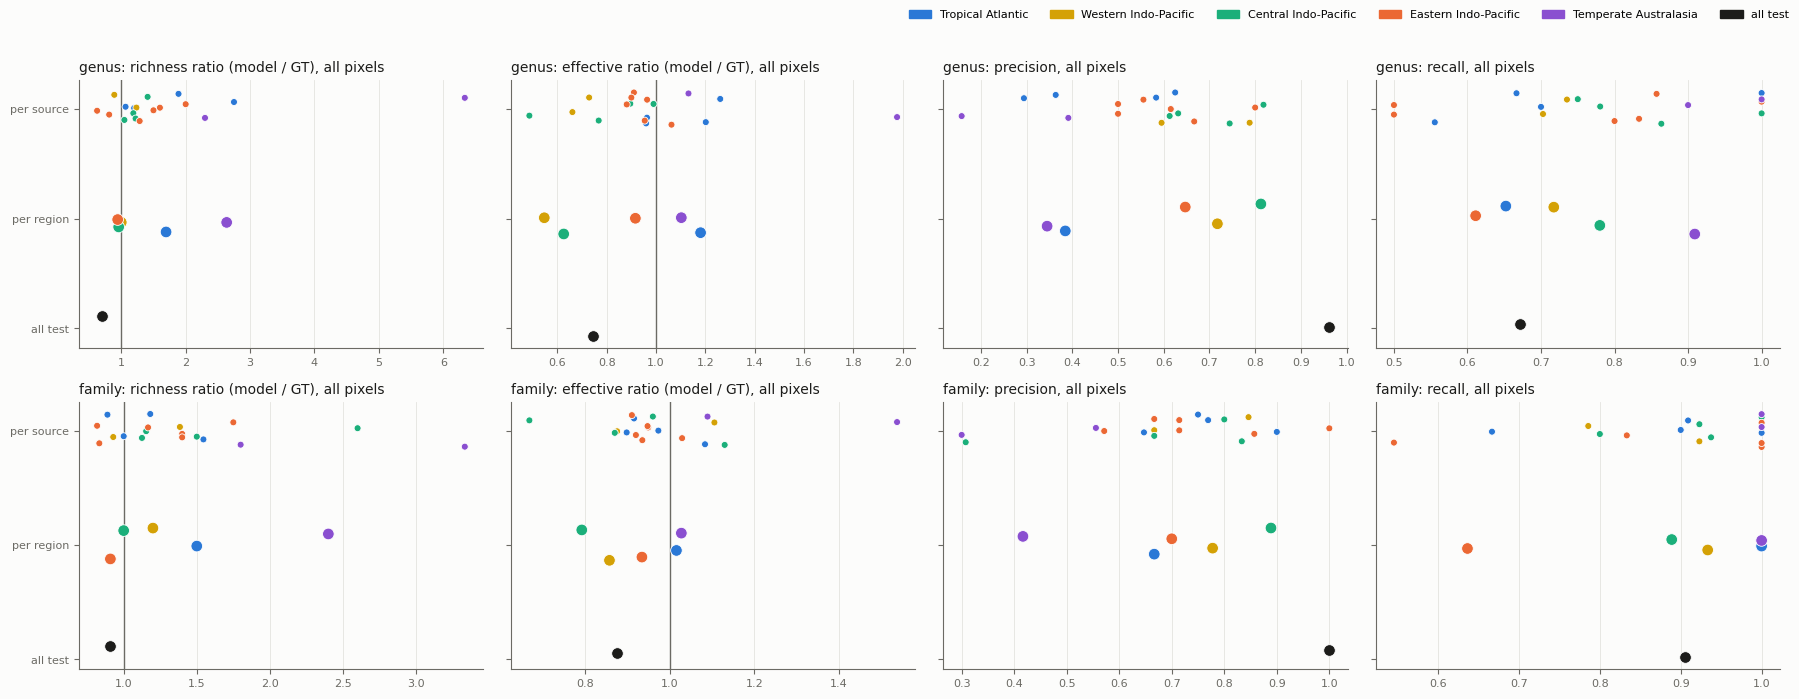

In [19]:
S = {"genus": S_GENUS, "family": S_FAMILY}
rows = []
for lvl in LEVELS:
    for scope in ("source", "region", "all"):
        t = S[lvl][scope]
        for key in MODEL_KEYS:
            rr = t[("richness", key)] / t[("richness", "truth")]
            er = t[("effective", key)] / t[("effective", "truth")]
            f = lambda x: f"{x.mean():.2f}" if len(x) == 1 else f"{x.mean():.2f} ({x.min():.2f}–{x.max():.2f})"
            rows.append({"level": lvl, "scope": scope, "estimate": ESTIMATES[key][0], "groups": len(t),
                         "richness ratio": f(rr), "effective ratio": f(er),
                         "precision": f(t[("precision", key)]), "recall": f(t[("recall", key)]),
                         "composition similarity": f(t[("composition similarity", key)])})
ACROSS = pd.DataFrame(rows).set_index(["level", "scope", "estimate"])
display(ACROSS)

fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey="row")
metrics = [("richness", True), ("effective", True), ("precision", False), ("recall", False)]
for i, lvl in enumerate(LEVELS):
    for ax, (m, is_ratio) in zip(axes[i], metrics):
        for j, scope in enumerate(("source", "region", "all")):
            t = S[lvl][scope]
            v = t[(m, "model_dense")] / t[(m, "truth")] if is_ratio else t[(m, "model_dense")]
            colors = [REGION_COLOR.get(REGION_OF.get(g, g), INK) for g in t.index]
            ax.scatter(v, j + rng.uniform(-0.15, 0.15, len(v)), c=colors, s=25 if scope == "source" else 70,
                       edgecolor="white", lw=0.6, zorder=3)
        if is_ratio:
            ax.axvline(1, color=MUTED, lw=1)
        ax.set_yticks(range(3), ["per source", "per region", "all test"])
        ax.grid(axis="y", visible=False)
        ax.set_title(f"{lvl}: {m}{' ratio (model / GT)' if is_ratio else ''}, all pixels")
    axes[i, 0].invert_yaxis()
fig.legend(handles=[Patch(color=c, label=r) for r, c in REGION_COLOR.items()] + [Patch(color=INK, label="all test")],
           loc="upper right", ncol=6, fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 5. How much does the pixel threshold matter?
For `TAU` from 0 (any pixel) to 10%, averaged over the eligible sources (all images), at each level. Dotted: the model
at the points.

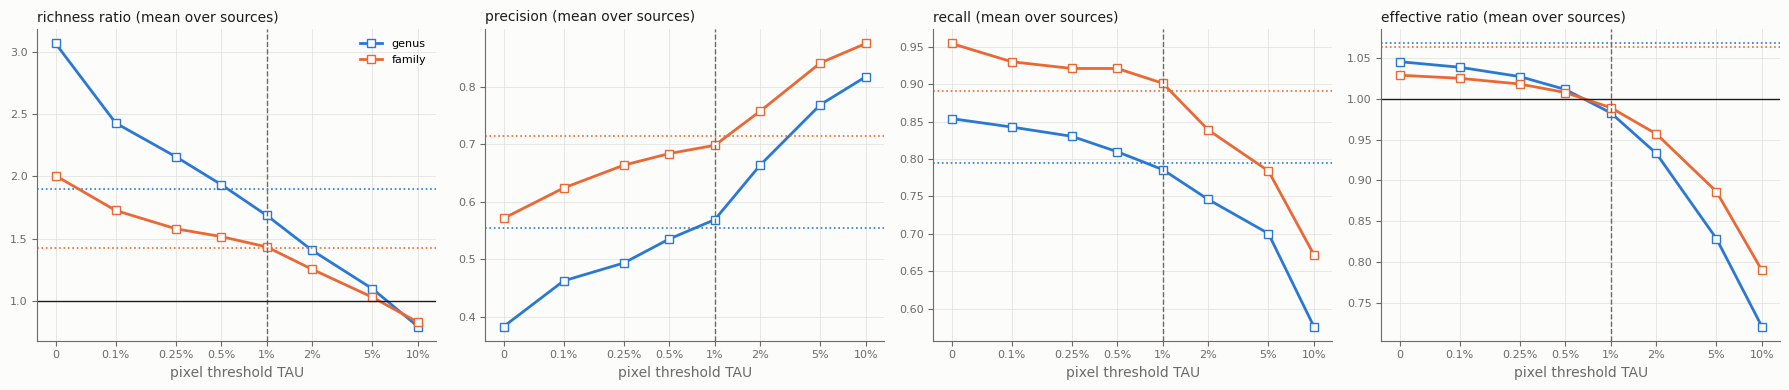

richness ratio       precision       recall       effective ratio      
level          family genus    family genus family genus          family genus
tau                                                                           
0.0000           2.01  3.07      0.57  0.38   0.95  0.85            1.03  1.05
0.0010           1.73  2.43      0.62  0.46   0.93  0.84            1.03  1.04
0.0025           1.58  2.16      0.66  0.49   0.92  0.83            1.02  1.03
0.0050           1.52  1.93      0.68  0.54   0.92  0.81            1.01  1.01
0.0100           1.43  1.69      0.70  0.57   0.90  0.79            0.99  0.98
0.0200           1.25  1.41      0.76  0.66   0.84  0.75            0.96  0.93
0.0500           1.03  1.10      0.84  0.77   0.78  0.70            0.89  0.83
0.1000           0.83  0.80      0.87  0.82   0.67  0.58            0.79  0.72

In [20]:
TAUS = [0.0, 0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.1]
sens = []
for lvl in LEVELS:
    for tau in TAUS:
        for g, rows in ROWS[lvl]["source"].items():
            gt = abundance(lvl, rows, "truth").sum(axis=0)
            a = abundance(lvl, rows, "model_dense", tau=tau).sum(axis=0)
            sens.append({"level": lvl, "tau": tau, "source": g, "richness ratio": (a > 0).sum() / (gt > 0).sum(),
                         "precision": ((a > 0) & (gt > 0)).sum() / max((a > 0).sum(), 1),
                         "recall": ((a > 0) & (gt > 0)).sum() / (gt > 0).sum(),
                         "effective ratio": hill1(a) / hill1(gt)})
sens = pd.DataFrame(sens)
mean = sens.groupby(["level", "tau"]).mean(numeric_only=True).reset_index()
lvl_color = {"genus": "#2a78d6", "family": "#eb6834"}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, metric in zip(axes, ["richness ratio", "precision", "recall", "effective ratio"]):
    for lvl in LEVELS:
        c = mean[mean.level == lvl]
        ax.plot(np.maximum(c.tau, 0.0004), c[metric], color=lvl_color[lvl], lw=2, marker="s", mfc=SURFACE, label=lvl)
        t = S[lvl]["source"]
        ref = {"richness ratio": (t[("richness", "model_points")] / t[("richness", "truth")]).mean(),
               "precision": t[("precision", "model_points")].mean(), "recall": t[("recall", "model_points")].mean(),
               "effective ratio": (t[("effective", "model_points")] / t[("effective", "truth")]).mean()}[metric]
        ax.axhline(ref, color=lvl_color[lvl], lw=1.2, ls=":")
    ax.axvline(TAU, color=MUTED, lw=1, ls="--")
    if "ratio" in metric:
        ax.axhline(1, color=INK, lw=1)
    ax.set_xscale("log")
    ax.set_xticks([0.0004, 0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.1],
                  ["0", "0.1%", "0.25%", "0.5%", "1%", "2%", "5%", "10%"])
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.set_xlabel("pixel threshold TAU")
    ax.set_title(f"{metric} (mean over sources)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
mean.pivot(index="tau", columns="level", values=["richness ratio", "precision", "recall", "effective ratio"]).round(2)

## 7. Comparing the confidence rules
**At the points.** Annotated live coral points with a genus (family), predicted live coral, from the eligible sources:
how many points each rule keeps, how often the kept genus (family) is right, and the share of correct calls lost.

In [21]:
rows = []
for lvl in LEVELS:
    pt = conf_pts[conf_pts.gt_live & conf_pts.pred_live & conf_pts[f"gt_{lvl}"].astype(str).isin(TAXA[lvl])
                  & conf_pts.source_id.isin(SRC[lvl])]
    correct = (pt[f"pred_{lvl}"].astype(str) == pt[f"gt_{lvl}"].astype(str)).to_numpy()
    p1, p2 = pt[f"pred_{lvl}_p1"].to_numpy(), pt[f"pred_{lvl}_p2"].to_numpy()
    for name, keep in (("all pixels", np.ones(len(pt), bool)), ("p1 ≥ 0.5", p1 >= 0.5), ("margin ≥ 0.25", p1 - p2 >= 0.25)):
        rows.append({"level": lvl, "rule": name, "points": len(pt), "kept": keep.mean(),
                     "accuracy, all": correct.mean(), "accuracy, kept": correct[keep].mean(),
                     "accuracy, dropped": correct[~keep].mean() if (~keep).any() else np.nan,
                     "correct calls lost": 1 - correct[keep].sum() / correct.sum()})
pd.DataFrame(rows).set_index(["level", "rule"]).round(3)

points   kept  accuracy, all  accuracy, kept  accuracy, dropped  correct calls lost
level  rule                                                                                              
genus  all pixels      72461  1.000          0.780           0.780                NaN               0.000
       p1 ≥ 0.5        72461  0.846          0.780           0.869              0.288               0.057
       margin ≥ 0.25   72461  0.850          0.780           0.859              0.330               0.064
family all pixels      75014  1.000          0.822           0.822                NaN               0.000
       p1 ≥ 0.5        75014  0.890          0.822           0.881              0.341               0.046
       margin ≥ 0.25   75014  0.879          0.822           0.881              0.394               0.058

**Per source: false and missed taxa.** False = predicted in the source (≥ `TAU` of an image's pixels in at least one
image) but never annotated there; missed = annotated but never predicted.

In [22]:
DENSE_KEYS = ["model_dense", "model_dense_p50", "model_dense_m25"]
rows = []
for lvl in LEVELS:
    for g, r in ROWS[lvl]["source"].items():
        gt = abundance(lvl, r, "truth").sum(axis=0) > 0
        row = {"level": lvl, "source": g, "region": REGION_OF[g], "annotated": int(gt.sum())}
        for k in DENSE_KEYS:
            pr = abundance(lvl, r, k).sum(axis=0) > 0
            row[("false", ESTIMATES[k][0])] = int((pr & ~gt).sum())
            row[("missed", ESTIMATES[k][0])] = int((gt & ~pr).sum())
        rows.append(row)
FM = pd.DataFrame(rows).set_index(["level", "source"])
FM.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, "") for c in FM.columns])
display(FM.groupby(level="level").sum(numeric_only=True).rename_axis("totals over sources"))
FM

,annotated,false,missed,false,missed,false,missed
,,"model, all pixels (≥1%)","model, all pixels (≥1%)","model, all pixels, p1 ≥ 0.5","model, all pixels, p1 ≥ 0.5","model, all pixels, margin ≥ 0.25","model, all pixels, margin ≥ 0.25"
totals over sources,,,,,,,
family,155,61,18,44,22,46,21
genus,299,165,71,99,95,105,92


region annotated                   false                  missed                       false                      missed                            false                           missed
                                               model, all pixels (≥1%) model, all pixels (≥1%) model, all pixels, p1 ≥ 0.5 model, all pixels, p1 ≥ 0.5 model, all pixels, margin ≥ 0.25 model, all pixels, margin ≥ 0.25
level  source                                                                                                                                                                                                           
genus  4091        Tropical Atlantic        15                       6                       5                           4                           5                                5                                5
       5181        Tropical Atlantic        20                      10                       6                           7                           8                                8                                8
       6494        Tropical Atlantic         9                      12                       4                           5                           4                                5                                4
       6702        Tropical Atlantic        12                      21                       0                          15                           0                               16                                0
       4721     Western Indo-Pacific        34                      17                       9                          11                          12                               12                               12
       4342     Western Indo-Pacific        37                       7                      11                           2                          13                                3                               13
       290      Central Indo-Pacific        22                      12                       3                           8                           7                                8                                6
       3606     Central Indo-Pacific        32                      14                       8                           9                           9                               10                                9
       4957     Central Indo-Pacific        41                      11                       9                          10                          13                               10                               12
       7116     Central Indo-Pacific        18                       4                       0                           2                           4                                3                                3
       1990     Eastern Indo-Pacific         4                       4                       0                           3                           0                                3                                0
       2682     Eastern Indo-Pacific         5                       4                       1                           3                           1                                3                                1
       3357     Eastern Indo-Pacific         6                       4                       1                           2                           1                                1                                1
       6405     Eastern Indo-Pacific         7                       3                       1                           2                           1                                2                                1
       3697     Eastern Indo-Pacific        16                       5                       8                           1                          10                                1                               10
       5227     Eastern Indo-Pacific         8                       1                       4                           1  

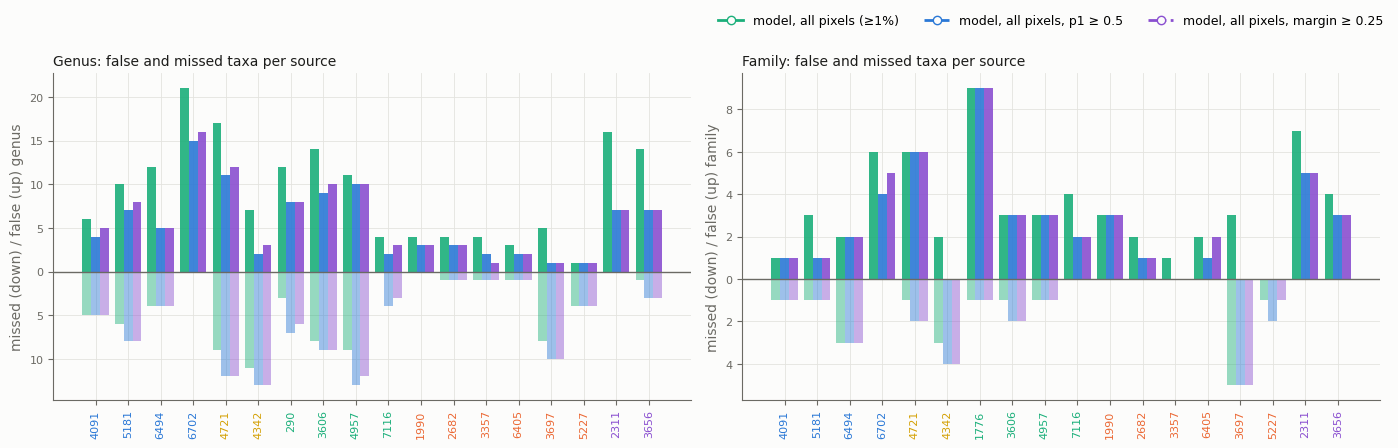

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, lvl in zip(axes, LEVELS):
    t = FM.loc[lvl]
    x = np.arange(len(t))
    for j, k in enumerate(DENSE_KEYS):
        _, color, _, _ = ESTIMATES[k]
        ax.bar(x + (j - 1) * 0.27, t[("false", ESTIMATES[k][0])], width=0.27, color=color, alpha=0.9)
        ax.bar(x + (j - 1) * 0.27, -t[("missed", ESTIMATES[k][0])], width=0.27, color=color, alpha=0.45)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xticks(x, t.index, rotation=90, fontsize=8)
    for lab, s in zip(ax.get_xticklabels(), t.index):
        lab.set_color(REGION_COLOR[REGION_OF[s]])
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{abs(v):g}"))
    ax.set_ylabel(f"missed (down) / false (up) {lvl}")
    ax.set_title(f"{lvl.capitalize()}: false and missed taxa per source")
legend(fig, keys=DENSE_KEYS, ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

The same counts as in `UseCase_Visualization.ipynb` (missed taxa to the left, false taxa to the right, one bar per
source, sources grouped by region and sorted by the number of annotated taxa), one row per all-pixel estimate. The x
axis is shared, so the rows compare directly.

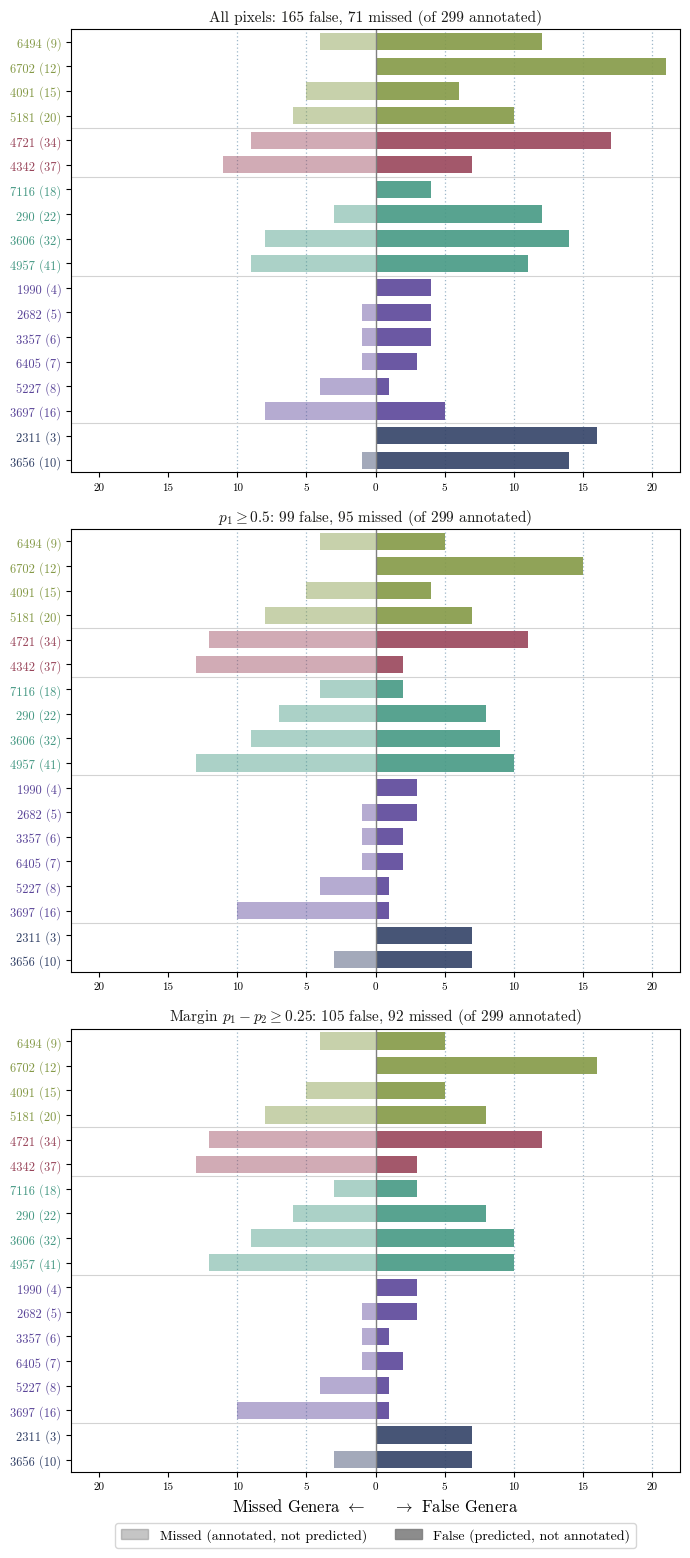

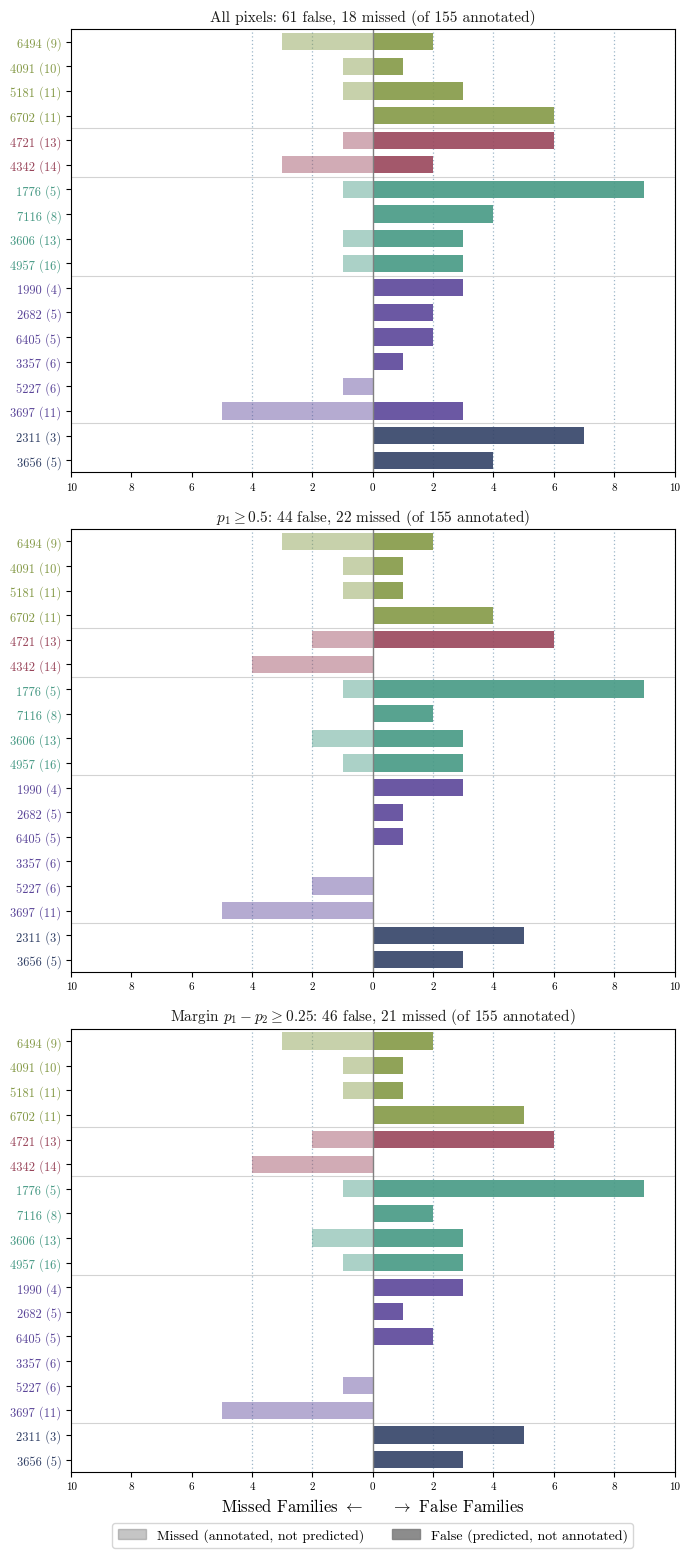

In [24]:
UC_COLORS = {"Tropical Atlantic": "#849946", "Western Indo-Pacific": "#99465b", "Central Indo-Pacific": "#469984",
             "Eastern Indo-Pacific": "#5b4699", "Temperate Australasia": "#334267"}  # as in UseCase_Visualization
UC_RC = {"font.family": "serif", "font.serif": ["cmr10", "Computer Modern Roman"], "mathtext.fontset": "cm",
         "axes.formatter.use_mathtext": True, "axes.titlelocation": "center", "axes.grid": False,
         "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
         "axes.edgecolor": "black", "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black",
         "axes.spines.top": True, "axes.spines.right": True, "legend.frameon": True}
RULE_TITLE = {"model_dense": "All pixels", "model_dense_p50": r"$p_1 \geq 0.5$",  # cmr10 has no ≥ glyph
              "model_dense_m25": r"Margin $p_1 - p_2 \geq 0.25$"}


def false_missed_rows(lvl, keys=DENSE_KEYS, lines=None):
    """Missed (left) / false (right) taxa per source, one row per all-pixel estimate in keys (UseCase_Visualization style)."""
    t = FM.loc[lvl].reset_index()
    t = pd.concat([t[t.region == r].sort_values("annotated") for r in REGIONS], ignore_index=True)
    PL = "Genera" if lvl == "genus" else "Families"
    xmax = max(max(t[("false", ESTIMATES[k][0])].max(), t[("missed", ESTIMATES[k][0])].max()) for k in keys) + 1
    lines = lines or ((-10, -5, 5, 10, 15, 20) if lvl == "genus" else (-4, -2, 2, 4, 6, 8, 10))
    with plt.rc_context(UC_RC):
        fig, axes = plt.subplots(len(keys), 1, figsize=(7, 5.2 * len(keys)), sharex=True)
        colors = t.region.map(UC_COLORS)
        y = np.arange(len(t))
        for ax, k in zip(axes, keys):
            false, missed = t[("false", ESTIMATES[k][0])], t[("missed", ESTIMATES[k][0])]
            ax.barh(y, -missed, color=colors, alpha=0.45, height=0.7)
            ax.barh(y, false, color=colors, alpha=0.9, height=0.7)
            for i in np.flatnonzero(t.region.ne(t.region.shift()))[1:]:  # separate the regions
                ax.axhline(i - 0.5, color="lightgray", lw=0.8)
            ax.axvline(0, color="gray", lw=1)
            for lv in lines:
                ax.axvline(lv, color="#9db7c9", ls=(0, (1, 2)), lw=0.9, zorder=0)
            ax.set_yticks(y, [f"{r.source} ({r.annotated})" for r in t[["source", "annotated"]].droplevel(1, axis=1).itertuples()],
                          fontsize=9)
            for lab, g in zip(ax.get_yticklabels(), t.region):
                lab.set_color(UC_COLORS[g])
            ax.set_ylim(len(t) - 0.5, -0.5)
            ax.set_xlim(-xmax, xmax)
            ax.set_title(f"{RULE_TITLE[k]}: {int(false.sum())} false, {int(missed.sum())} missed "
                         f"(of {int(t.annotated.sum())} annotated)", fontsize=11)
            ax.xaxis.set_tick_params(labelbottom=True)
            ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
            ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(v):g}"))
        axes[-1].set_xlabel(rf"Missed {PL} $\leftarrow$ $\quad$ $\rightarrow$ False {PL}", fontsize=12)
        axes[-1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color="gray", alpha=0.45, label="Missed (annotated, not predicted)"),
                                 plt.Rectangle((0, 0), 1, 1, color="gray", alpha=0.9, label="False (predicted, not annotated)")],
                        fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
        fig.tight_layout()
        plt.show()


false_missed_rows("genus")
false_missed_rows("family")

**Confidence rule or a higher pixel threshold?** Both remove false taxa, so compare them at the same precision: for each
rule, `TAU` from 0 to 5%, mean over the eligible sources (as in section 5). A rule is better if its curve lies above
the others (more of the annotated taxa found at the same share of correct taxa). Labels: `TAU`.

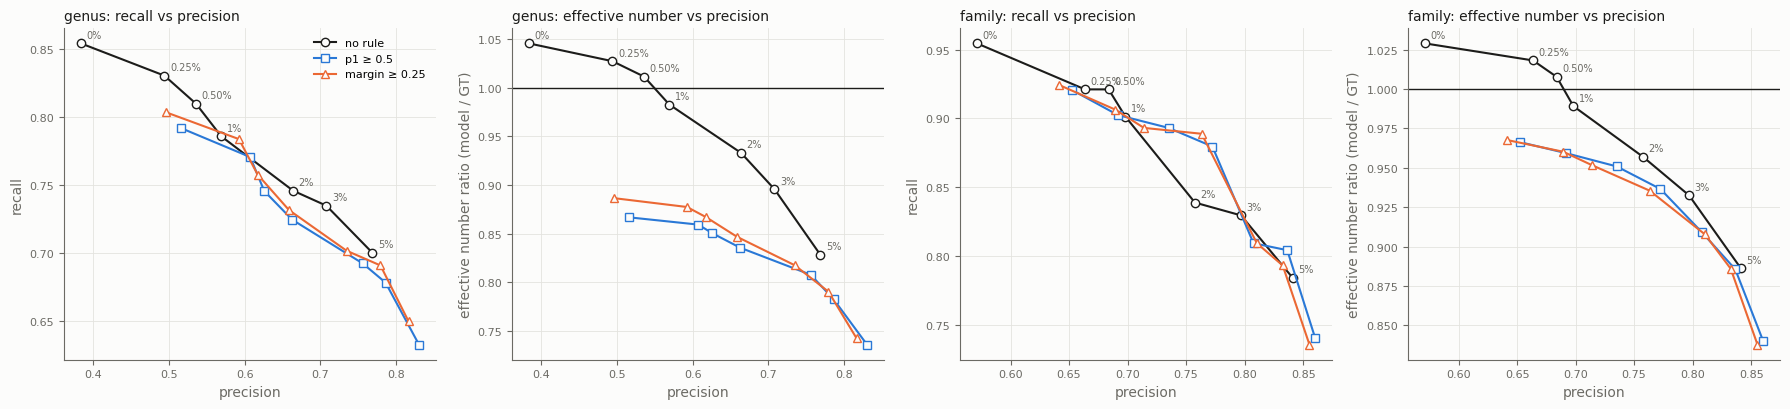

rule           margin ≥ 0.25                                         no rule                                        p1 ≥ 0.5                                 
              richness ratio precision recall effective ratio richness ratio precision recall effective ratio richness ratio precision recall effective ratio
level  tau                                                                                                                                                   
genus  0.0000           2.13      0.50   0.80            0.89           3.07      0.38   0.85            1.05           1.91      0.52   0.79            0.87
       0.0025           1.59      0.59   0.78            0.88           2.16      0.49   0.83            1.03           1.44      0.61   0.77            0.86
       0.0050           1.44      0.62   0.76            0.87           1.93      0.54   0.81            1.01           1.35      0.63   0.75            0.85
       0.0100           1.24      0.66   0.73            0.85           1.69      0.57   0.79            0.98           1.22      0.66   0.72            0.84
       0.0200           1.09      0.73   0.70            0.82           1.41      0.66   0.75            0.93           1.04      0.76   0.69            0.81
       0.0300           1.00      0.78   0.69            0.79           1.29      0.71   0.73            0.90           0.95      0.79   0.68            0.78
       0.0500           0.87      0.82   0.65            0.74           1.10      0.77   0.70            0.83           0.83      0.83   0.63            0.74
family 0.0000           1.65      0.64   0.92            0.97           2.01      0.57   0.95            1.03           1.60      0.65   0.92            0.97
       0.0025           1.47      0.69   0.91            0.96           1.58      0.66   0.92            1.02           1.43      0.69   0.90            0.96
       0.0050           1.38      0.71   0.89            0.95           1.52      0.68   0.92            1.01           1.35      0.74   0.89            0.95
       0.0100           1.30      0.76   0.89            0.94           1.43      0.70   0.90            0.99           1.28      0.77   0.88            0.94
       0.0200           1.11      0.81   0.81            0.91           1.25      0.76   0.84            0.96           1.11      0.81   0.81            0.91
       0.0300           1.04      0.83   0.79            0.89           1.17      0.80   0.83            0.93           1.04      0.84   0.80            0.89
       0.0500           0.92      0.86   0.74            0.84           1.03      0.84   0.78            0.89           0.92      0.86   0.74            0.84

In [25]:
TAUS_GRID = [0.0, 0.0025, 0.005, 0.01, 0.02, 0.03, 0.05]
RULES = {"model_dense": "no rule", "model_dense_p50": "p1 ≥ 0.5", "model_dense_m25": "margin ≥ 0.25"}
grid = []
for lvl in LEVELS:
    for key in RULES:
        for tau in TAUS_GRID:
            for g, rows in ROWS[lvl]["source"].items():
                gt = abundance(lvl, rows, "truth").sum(axis=0)
                a = abundance(lvl, rows, key, tau=tau).sum(axis=0)
                grid.append({"level": lvl, "rule": RULES[key], "tau": tau,
                             "richness ratio": (a > 0).sum() / (gt > 0).sum(),
                             "precision": ((a > 0) & (gt > 0)).sum() / max((a > 0).sum(), 1),
                             "recall": ((a > 0) & (gt > 0)).sum() / (gt > 0).sum(),
                             "effective ratio": hill1(a) / hill1(gt)})
GRID = pd.DataFrame(grid).groupby(["level", "rule", "tau"], sort=False).mean(numeric_only=True)

rule_style = {"no rule": (INK, "o"), "p1 ≥ 0.5": ("#2a78d6", "s"), "margin ≥ 0.25": ("#eb6834", "^")}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for i, lvl in enumerate(LEVELS):
    for rule, (c, m) in rule_style.items():
        t = GRID.loc[(lvl, rule)]
        for ax, y in ((axes[2 * i], "recall"), (axes[2 * i + 1], "effective ratio")):
            ax.plot(t.precision, t[y], color=c, marker=m, mfc=SURFACE, lw=1.5, label=rule)
            if rule == "no rule":
                for tau, r in t.iterrows():
                    ax.annotate(f"{tau:.2%}".replace(".00%", "%"), (r.precision, r[y]), xytext=(4, 4),
                                textcoords="offset points", fontsize=7, color=MUTED)
    axes[2 * i].set(xlabel="precision", ylabel="recall", title=f"{lvl}: recall vs precision")
    axes[2 * i + 1].set(xlabel="precision", ylabel="effective number ratio (model / GT)",
                        title=f"{lvl}: effective number vs precision")
    axes[2 * i + 1].axhline(1, color=INK, lw=1)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
GRID.round(2).unstack("rule").swaplevel(0, 1, axis=1).sort_index(axis=1, level=0, sort_remaining=False)

## 8. Findings
Model `cbm_cd275000_res768` (step 50k) at 768 px. Eligible sources: 18 at each level, **including 4721** (excluded in
`UseCase_Visualization.ipynb`). Numbers per source are means over the 18 sources.

**At the points, confidence separates right from wrong genus calls well, and the two rules are almost the same.**
Of 72,461 annotated live coral points with a genus that are predicted live coral, p1 ≥ 0.5 keeps 85% and raises genus
accuracy from 0.78 to 0.87. The dropped calls are right only 29% of the time, and 5.7% of all correct calls are lost.
Margin ≥ 0.25 keeps 85% at 0.86 accuracy and loses 6.4% of correct calls. At family level: accuracy 0.82 → 0.88 for
both rules, keeping 89% (p1) / 88% (margin). p1 ≥ 0.5 is marginally better at both levels.

**Per source, the rules cut false genera by about 40% but miss more.** Summed over the 18 sources, false genera go
from 165 to 99 (p1) / 105 (margin) and missed genera from 71 to 95 / 92 (of 299 annotated). Families: false 61 → 44 /
46, missed 18 → 22 / 21 (of 155). Genus richness ratio 1.69 → 1.22 (p1) / 1.24 (margin), precision 0.57 → 0.66,
recall 0.79 → 0.72. Per region the richness ratio drops from 1.45 to 1.02.

**But the effective number gets worse, and pooled over all test data the rules hurt.** The genus effective-number
ratio drops from 0.98 to 0.84 per source and from 0.74 to 0.63 for all test data. Pooled, the model already finds too
few genera (53 of 76 annotated); the rules bring that to 46 (p1) / 47 (margin) and recall from 0.67 to 0.59 / 0.61.
The rules remove pixels of the less common genera more than of the dominant ones (the model is less sure of them), so
the remaining abundances are more uneven than the annotations. Family-level pooled richness is unchanged (19 of 21).

**At genus level, a higher pixel threshold does as well as either rule** (section 7, last figure). At the precision
the rules reach (0.66, p1 ≥ 0.5 at `TAU` = 1%), no rule at `TAU` = 2% gives the same precision with higher recall
(0.75 vs 0.72) and a much better effective ratio (0.93 vs 0.84). At `TAU` = 5% without a rule: precision 0.77, recall
0.70, effective 0.83, against 0.76 / 0.69 / 0.81 for p1 ≥ 0.5 at 2%. **At family level the rules help a little:** p1 ≥
0.5 at 1% gives precision 0.77 with recall 0.88; no rule needs `TAU` ≈ 2–3% for that precision, with recall 0.83–0.84. Above precision 0.8 the three curves meet.

**Recommendation.** For genus diversity, raise the pixel threshold (2% for balance, 5% for a richness ratio near 1)
instead of adding a confidence rule: same precision, more taxa found, abundances closer to the annotations. At family
level p1 ≥ 0.5 at 1% adds about 4 points of recall at equal precision (0.77), but nothing at higher precision. No setting fixes the pooled under-count of rare genera:
every way of removing false taxa also removes some true rare ones.